In [1]:
import os

# Voir les fichiers disponibles dans data/
print(os.listdir("../data/"))

FileNotFoundError: [WinError 3] Le chemin d’accès spécifié est introuvable: '../data/'

In [15]:
import zipfile
import os

# Extraire le zip
with zipfile.ZipFile("../data/archive (3).zip", "r") as zip_ref:
    zip_ref.extractall("../data/")

# Voir les fichiers extraits
print(os.listdir("../data/"))

['archive (3).zip', 'PS_20174392719_1491204439457_log.csv']


In [1]:
import pandas as pd
df = pd.read_csv("../data/PS_20174392719_1491204439457_log.csv")
print(df.shape)
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '../data/PS_20174392719_1491204439457_log.csv'

In [17]:
# Infos générales
print(df.info())
print(df.describe())

# Distribution des fraudes
print(df['isFraud'].value_counts())
print(df['isFraud'].value_counts(normalize=True) * 100)

# Types de transactions
print(df['type'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB
None
               step        amount  oldbalanceOrg  newbalanceOrig  \
count  6.362620e+06  6.362620e+06   6.362620e+06    6.362620e+06   
mean   2.433972e+02  1.798619e+05   8.338831e+05    8.551137e+05   
std    1.423320e+02  6.038582e+05   2.888243e+06    2.924049e+06   
min    1.000000e+00  0.000000e+00   0.000000e+00    0.000000e+00   
25%    1.560000e+02  1.338957e+04   0.000000e+00    0.000000e+00   
50%    2.390000e+02  7.487194e+04

In [18]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

In [19]:
df = pd.read_csv("../data/PS_20174392719_1491204439457_log.csv")
print("✅ Shape :", df.shape)
print(df.head())

✅ Shape : (6362620, 11)
   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C1305486145          181.0            0.00   
3     1  CASH_OUT    181.00   C840083671          181.0            0.00   
4     1   PAYMENT  11668.14  C2048537720        41554.0        29885.86   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979787155             0.0             0.0        0               0  
1  M2044282225             0.0             0.0        0               0  
2   C553264065             0.0             0.0        1               0  
3    C38997010         21182.0             0.0        1               0  
4  M1230701703             0.0             0.0        0               0  



 Valeurs manquantes


In [20]:
print("Valeurs manquantes :")
print(df.isnull().sum())

# Doublons
print("\nDoublons :", df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("✅ Nettoyage terminé")

Valeurs manquantes :
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Doublons : 0
✅ Nettoyage terminé


In [21]:
le = LabelEncoder()
df['type_encoded'] = le.fit_transform(df['type'])

print("Encodage 'type' :")
print(dict(zip(le.classes_, le.transform(le.classes_))))

Encodage 'type' :
{'CASH_IN': 0, 'CASH_OUT': 1, 'DEBIT': 2, 'PAYMENT': 3, 'TRANSFER': 4}


 Erreur de balance: important pour détecter la fraude

In [22]:
# Erreur de balance (très important pour détecter la fraude)
df['errorBalanceOrig'] = df['newbalanceOrig'] + df['amount'] - df['oldbalanceOrg']
df['errorBalanceDest'] = df['oldbalanceDest'] + df['amount'] - df['newbalanceDest']

# Compte vidé = suspect
df['isZeroOrig'] = (df['oldbalanceOrg'] == 0).astype(int)
df['isZeroDest']  = (df['newbalanceDest'] == 0).astype(int)

# Ratio montant / solde
df['amountRatio'] = df['amount'] / (df['oldbalanceOrg'] + 1)

# Nombre de transactions par heure
tx_per_step = df.groupby('step')['amount'].count().reset_index()
tx_per_step.columns = ['step', 'nb_tx_step']
df = df.merge(tx_per_step, on='step', how='left')

# Montant moyen par type
df['avg_amount_by_type'] = df.groupby('type_encoded')['amount'].transform('mean')

# Transaction anormalement grande ?
df['is_large_tx'] = (df['amount'] > df['avg_amount_by_type'] * 2).astype(int)

print("✅ Nouvelles features créées :")
print(df[['errorBalanceOrig','errorBalanceDest','isZeroOrig',
          'isZeroDest','amountRatio','nb_tx_step','is_large_tx']].head())

✅ Nouvelles features créées :
   errorBalanceOrig  errorBalanceDest  isZeroOrig  isZeroDest  amountRatio  \
0               0.0           9839.64           0           1     0.057834   
1               0.0           1864.28           0           1     0.087731   
2               0.0            181.00           0           1     0.994505   
3               0.0          21363.00           0           1     0.994505   
4               0.0          11668.14           0           1     0.280788   

   nb_tx_step  is_large_tx  
0        2708            0  
1        2708            0  
2        2708            0  
3        2708            0  
4        2708            0  


In [23]:
FEATURES = [
    'type_encoded', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest', 'errorBalanceOrig',
    'errorBalanceDest', 'isZeroOrig', 'isZeroDest',
    'amountRatio', 'nb_tx_step', 'is_large_tx'
]
TARGET = 'isFraud'

X = df[FEATURES]
y = df[TARGET]

print("Features sélectionnées :", len(FEATURES))
print("Distribution cible :")
print(y.value_counts())

Features sélectionnées : 13
Distribution cible :
isFraud
0    6354407
1       8213
Name: count, dtype: int64


Normalisation 

In [24]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=FEATURES)
print(X_scaled.describe().round(2))

       type_encoded      amount  oldbalanceOrg  newbalanceOrig  \
count    6362620.00  6362620.00     6362620.00      6362620.00   
mean          -0.00       -0.00          -0.00            0.00   
std            1.00        1.00           1.00            1.00   
min           -1.27       -0.30          -0.29           -0.29   
25%           -0.53       -0.28          -0.29           -0.29   
50%           -0.53       -0.17          -0.28           -0.29   
75%            0.95        0.05          -0.25           -0.24   
max            1.69      152.79          20.34           16.67   

       oldbalanceDest  newbalanceDest  errorBalanceOrig  errorBalanceDest  \
count      6362620.00      6362620.00        6362620.00        6362620.00   
mean             0.00           -0.00              0.00             -0.00   
std              1.00            1.00              1.00              1.00   
min             -0.32           -0.33             -0.33           -172.00   
25%             -0.3

In [25]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import pandas as pd

# ── Split ──────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"✅ Train : {X_train.shape[0]:,} lignes")
print(f"✅ Test  : {X_test.shape[0]:,} lignes")
print(f"Fraudes train : {y_train.sum():,} ({y_train.mean()*100:.2f}%)")

✅ Train : 5,090,096 lignes
✅ Test  : 1,272,524 lignes
Fraudes train : 6,570 (0.13%)


In [26]:
import joblib
import os

os.makedirs('../Models', exist_ok=True)

joblib.dump(
    (X_train, X_test, y_train, y_test,
     X_train, y_train, scaler, FEATURES),
    '../Models/data_prepared.pkl'
)

print("✅ Données sauvegardées → Models/data_prepared.pkl")

✅ Données sauvegardées → Models/data_prepared.pkl


In [15]:
pip install "numpy<2"

In [16]:
pip install matplotlib seaborn scikit-learn imbalanced-learn --upgrade

Note: you may need to restart the kernel to use updated packages.
  Using cached matplotlib-3.11.1-cp312-cp312-win_amd64.whl.metadata (80 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB 330.3 kB/s eta 0:00:29
   ---------------------------------------- 0.1/9.3 MB 655.4 kB/s eta 0:00:15
    --------------------------------------- 0.2/9.3 MB 1.1 MB/s eta 0:00:08
   - -------------------------------------- 0.4/9.3 MB 1.7 MB/s eta 0:00:06
   -- ------------------------------------- 0.6/9.3 MB 1.9 MB/s eta 0:00:05
   -- ------------------------------------- 0.7/9.3 MB 2.0 MB/s eta 0:00:05
   --- ------------------------------------ 0.8/9.3 MB 2.1 MB/s eta 0:00:05
   ---- ----------------------------------- 1.0/9.3 MB 2.2 MB/s eta 0:00:04
   ---- ----------------------------------- 1.0/9.3 MB 2.2 MB/s eta 0:00:04
   ---- ------------------------

In [27]:
import numpy as np
import matplotlib
import seaborn as sns
import sklearn
import imblearn

print("✅ NumPy          :", np.__version__)
print("✅ Matplotlib     :", matplotlib.__version__)
print("✅ Seaborn        :", sns.__version__)
print("✅ Scikit-learn   :", sklearn.__version__)
print("✅ Imbalanced-learn:", imblearn.__version__)

✅ NumPy          : 1.26.4
✅ Matplotlib     : 3.11.1
✅ Seaborn        : 0.13.2
✅ Scikit-learn   : 1.9.0
✅ Imbalanced-learn: 0.14.2


In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

os.makedirs('../Models', exist_ok=True)
plt.style.use('seaborn-v0_8')


SANS SMOTE 

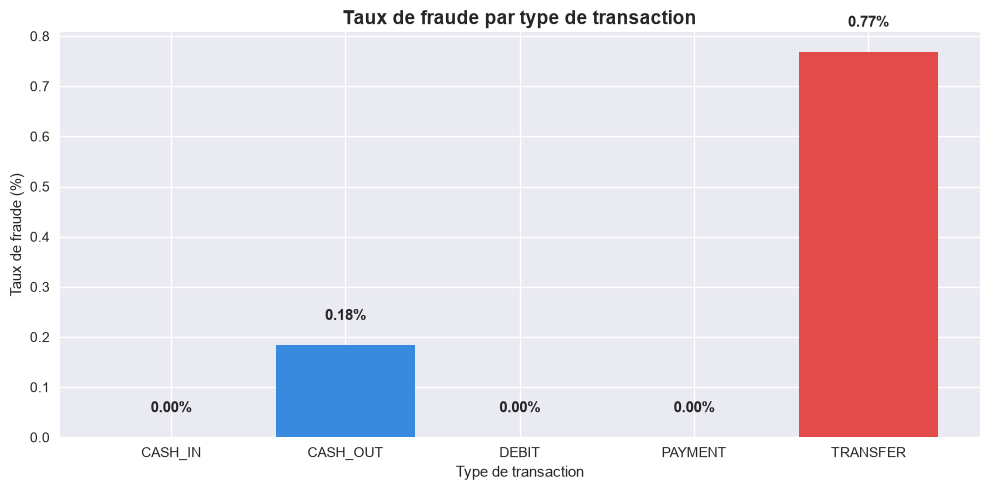

In [31]:
fraud_by_type = df.groupby('type')['isFraud'].agg(['sum', 'count'])
fraud_by_type['taux'] = fraud_by_type['sum'] / fraud_by_type['count'] * 100

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(fraud_by_type.index, fraud_by_type['taux'],
              color=['#E24B4A' if t > 0.5 else '#378ADD'
                     for t in fraud_by_type['taux']])

for bar, val in zip(bars, fraud_by_type['taux']):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.05,
            f'{val:.2f}%', ha='center', fontsize=11, fontweight='bold')

ax.set_title('Taux de fraude par type de transaction', fontsize=14, fontweight='bold')
ax.set_xlabel('Type de transaction')
ax.set_ylabel('Taux de fraude (%)')
plt.tight_layout()
plt.savefig('../Models/g1_fraude_par_type.png', dpi=150)
plt.show()

In [32]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv("../data/PS_20174392719_1491204439457_log.csv")

le = LabelEncoder()
df['type_encoded'] = le.fit_transform(df['type'])
df['errorBalanceOrig'] = df['newbalanceOrig'] + df['amount'] - df['oldbalanceOrg']
df['errorBalanceDest'] = df['oldbalanceDest'] + df['amount'] - df['newbalanceDest']
df['amountRatio'] = df['amount'] / (df['oldbalanceOrg'] + 1)
df['avg_amount_by_type'] = df.groupby('type_encoded')['amount'].transform('mean')
df['is_large_tx'] = (df['amount'] > df['avg_amount_by_type'] * 2).astype(int)

print("✅ Données rechargées :", df.shape)

✅ Données rechargées : (6362620, 17)


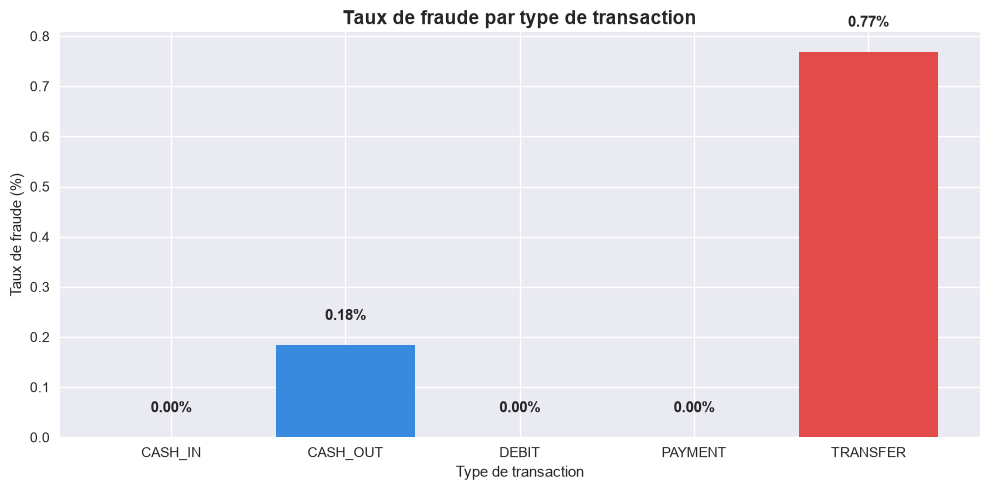

In [33]:
fraud_by_type = df.groupby('type')['isFraud'].agg(['sum', 'count'])
fraud_by_type['taux'] = fraud_by_type['sum'] / fraud_by_type['count'] * 100

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(fraud_by_type.index, fraud_by_type['taux'],
              color=['#E24B4A' if t > 0.5 else '#378ADD'
                     for t in fraud_by_type['taux']])

for bar, val in zip(bars, fraud_by_type['taux']):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.05,
            f'{val:.2f}%', ha='center', fontsize=11, fontweight='bold')

ax.set_title('Taux de fraude par type de transaction', fontsize=14, fontweight='bold')
ax.set_xlabel('Type de transaction')
ax.set_ylabel('Taux de fraude (%)')
plt.tight_layout()
plt.savefig('../Models/g1_fraude_par_type.png', dpi=150)
plt.show()

 Vérification complète

In [34]:
print("="*50)
print("RAPPORT DE QUALITÉ DES DONNÉES")
print("="*50)

# Dimensions
print(f"\n📐 Dimensions : {df.shape[0]:,} lignes · {df.shape[1]} colonnes")

# Valeurs manquantes
print("\n📋 Valeurs manquantes :")
missing = df.isnull().sum()
if missing.sum() == 0:
    print("   ✅ Aucune valeur manquante !")
else:
    print(missing[missing > 0])

# Doublons
print(f"\n📋 Doublons : ", end="")
dupl = df.duplicated().sum()
if dupl == 0:
    print("✅ Aucun doublon !")
else:
    print(f"⚠️ {dupl:,} doublons trouvés")

# Types de colonnes
print("\n📋 Types des colonnes :")
print(df.dtypes)

RAPPORT DE QUALITÉ DES DONNÉES

📐 Dimensions : 6,362,620 lignes · 17 colonnes

📋 Valeurs manquantes :
   ✅ Aucune valeur manquante !

📋 Doublons : ✅ Aucun doublon !

📋 Types des colonnes :
step                    int64
type                   object
amount                float64
nameOrig               object
oldbalanceOrg         float64
newbalanceOrig        float64
nameDest               object
oldbalanceDest        float64
newbalanceDest        float64
isFraud                 int64
isFlaggedFraud          int64
type_encoded            int32
errorBalanceOrig      float64
errorBalanceDest      float64
amountRatio           float64
avg_amount_by_type    float64
is_large_tx             int32
dtype: object


In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve,
                             f1_score, precision_score,
                             recall_score, accuracy_score)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import joblib
import os

os.makedirs('../Models', exist_ok=True)
print("✅ Imports OK")

✅ Imports OK


 Créer les colonnes manquantes

In [36]:

df['isZeroOrig'] = (df['oldbalanceOrg'] == 0).astype(int)
df['isZeroDest']  = (df['newbalanceDest'] == 0).astype(int)

tx_per_step = df.groupby('step')['amount'].count().reset_index()
tx_per_step.columns = ['step', 'nb_tx_step']
df = df.merge(tx_per_step, on='step', how='left')

print("✅ Colonnes ajoutées !")
print("Colonnes disponibles :", list(df.columns))

✅ Colonnes ajoutées !
Colonnes disponibles : ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'type_encoded', 'errorBalanceOrig', 'errorBalanceDest', 'amountRatio', 'avg_amount_by_type', 'is_large_tx', 'isZeroOrig', 'isZeroDest', 'nb_tx_step']


In [37]:
from sklearn.model_selection import train_test_split

FEATURES = [
    'type_encoded', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest', 'errorBalanceOrig',
    'errorBalanceDest', 'isZeroOrig', 'isZeroDest',
    'amountRatio', 'nb_tx_step', 'is_large_tx'
]

# Vérifier les colonnes manquantes
missing_cols = [c for c in FEATURES if c not in df.columns]
if missing_cols:
    print(f"⚠️ Colonnes manquantes : {missing_cols}")
else:
    print("✅ Toutes les features sont présentes")

# Variables explicatives et cible
X = df[FEATURES]
y = df['isFraud']

# Division Train / Test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"✅ Train : {X_train.shape[0]:,} | Test : {X_test.shape[0]:,}")

# Vérification de la distribution des classes
print("\nRépartition des classes dans le train :")
print(pd.Series(y_train).value_counts())

print("\nRépartition des classes dans le test :")
print(pd.Series(y_test).value_counts())

✅ Toutes les features sont présentes
✅ Train : 5,090,096 | Test : 1,272,524

Répartition des classes dans le train :
isFraud
0    5083526
1       6570
Name: count, dtype: int64

Répartition des classes dans le test :
isFraud
0    1270881
1       1643
Name: count, dtype: int64


Tableau comparatif


In [39]:
print("🔹 Logistic Regression en cours...")

lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]

print("\n📊 Résultats Logistic Regression :")
print(classification_report(y_test, y_pred_lr,
      target_names=['Légitime', 'Fraude']))
print(f"AUC-ROC : {roc_auc_score(y_test, y_prob_lr):.4f}")

🔹 Logistic Regression en cours...

📊 Résultats Logistic Regression :
              precision    recall  f1-score   support

    Légitime       1.00      0.95      0.98   1270881
      Fraude       0.03      0.94      0.05      1643

    accuracy                           0.95   1272524
   macro avg       0.51      0.94      0.51   1272524
weighted avg       1.00      0.95      0.97   1272524

AUC-ROC : 0.9831


Interpretation a completer 

Random Forest

In [40]:
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve,
                             f1_score, precision_score,
                             recall_score, accuracy_score)
print("✅ Imports OK")

✅ Imports OK


In [41]:
rf = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    max_depth=20,
    random_state=42,
    n_jobs=2
)

rf.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_featu

In [42]:
print(X_train.shape)

(5090096, 13)


In [43]:
print(y_train.value_counts())

isFraud
0    5083526
1       6570
Name: count, dtype: int64


In [44]:
# Prédictions
y_pred_rf = rf.predict(X_test)

# Probabilités
y_prob_rf = rf.predict_proba(X_test)[:, 1]

# Rapport de classification
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=['Légitime', 'Fraude']
))

# AUC
print("AUC-ROC :", roc_auc_score(y_test, y_prob_rf))

              precision    recall  f1-score   support

    Légitime       1.00      1.00      1.00   1270881
      Fraude       1.00      1.00      1.00      1643

    accuracy                           1.00   1272524
   macro avg       1.00      1.00      1.00   1272524
weighted avg       1.00      1.00      1.00   1272524

AUC-ROC : 0.9990863105946399


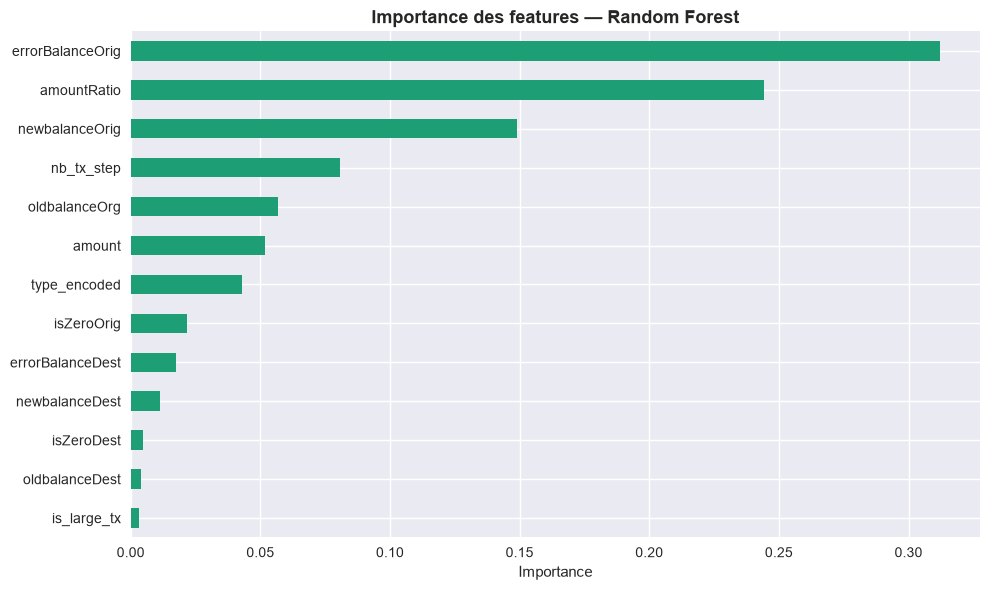

🏆 Classement complet des features :
errorBalanceOrig    0.311954
amountRatio         0.244375
newbalanceOrig      0.148859
nb_tx_step          0.080821
oldbalanceOrg       0.056944
amount              0.051601
type_encoded        0.042920
isZeroOrig          0.021781
errorBalanceDest    0.017651
newbalanceDest      0.011129
isZeroDest          0.004772
oldbalanceDest      0.003891
is_large_tx         0.003302


In [34]:
feat_imp = pd.Series(
    rf.feature_importances_,
    index=FEATURES
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
feat_imp.plot(kind='barh', ax=ax, color='#1D9E75')
ax.invert_yaxis()  # la plus importante en haut
ax.set_title('Importance des features — Random Forest',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig('../Models/feature_importance.png', dpi=150)
plt.show()

print("🏆 Classement complet des features :")
print(feat_imp.to_string())

In [35]:
iso = IsolationForest(
    contamination=0.001,   # proportion attendue d'anomalies
    random_state=42,
    n_jobs=-1
)
iso.fit(X_train)

# -1 = anomalie détectée → on le convertit en 1 (fraude)
y_pred_iso_raw = iso.predict(X_test)
y_pred_iso = np.where(y_pred_iso_raw == -1, 1, 0)

print("\n📊 Résultats Isolation Forest :")
print(classification_report(y_test, y_pred_iso,
      target_names=['Légitime', 'Fraude']))

print(f"AUC-ROC : {roc_auc_score(y_test, y_pred_iso):.4f}")


📊 Résultats Isolation Forest :
              precision    recall  f1-score   support

    Légitime       1.00      1.00      1.00   1270881
      Fraude       0.00      0.00      0.00      1643

    accuracy                           1.00   1272524
   macro avg       0.50      0.50      0.50   1272524
weighted avg       1.00      1.00      1.00   1272524

AUC-ROC : 0.4995


DL

Préparation des données pour l'autoencoder

In [38]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix


In [39]:
data = joblib.load('../Models/data_prepared.pkl')
X_train, X_test, y_train, y_test, X_train_sm, y_train_sm, scaler, FEATURES = data

print(f"Shape X_train: {X_train.shape}")
print(f"Shape X_test: {X_test.shape}")

Shape X_train: (5090096, 13)
Shape X_test: (1272524, 13)


Pour l'autoencoder, on n'utilise QUE les transactions légitimes (isFraud=0)
On va prendre les données avant SMOTE pour avoir les vraies distributions


In [40]:
X_train_legit = X_train[y_train == 0]
print(f"✅ Transactions légitimes pour l'entraînement: {X_train_legit.shape[0]:,}")

✅ Transactions légitimes pour l'entraînement: 5,083,526


In [41]:
print(f"✅ Shape finale: {X_train_legit.shape}")

✅ Shape finale: (5083526, 13)


In [42]:
from sklearn.neural_network import MLPClassifier

ann = MLPClassifier(
    hidden_layer_sizes=(32, 16),  # 2 couches seulement
    activation='relu',
    solver='adam',
    max_iter=20,               # 20 itérations max 
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=3,       
    tol=1e-3,                
    verbose=True
)

ann.fit(X_train_sm, y_train_sm)

Iteration 1, loss = 0.03030269
Validation score: 0.994065
Iteration 2, loss = 0.01798085
Validation score: 0.991953
Iteration 3, loss = 0.01606534
Validation score: 0.995497
Iteration 4, loss = 0.01495473
Validation score: 0.995112
Iteration 5, loss = 0.01420042
Validation score: 0.994947
Iteration 6, loss = 0.01383100
Validation score: 0.996506
Iteration 7, loss = 0.01337816
Validation score: 0.996514
Iteration 8, loss = 0.01287063
Validation score: 0.995193
Iteration 9, loss = 0.01272156
Validation score: 0.995383
Iteration 10, loss = 0.01245863
Validation score: 0.996620
Validation score did not improve more than tol=0.001000 for 3 consecutive epochs. Stopping.


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(32, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",20
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"tol tol: float, default=1e-4Tolerance for the optimization. When the loss or score is not improvingby at least ``tol`` for ``n_iter_no_change`` consecutive iterations,unless ``learning_rate`` is set to 'adaptive', convergence isconsidered to be reached and training stops.",0.001
,"verbose verbose: bool, default=FalseWhether to print progress messages to stdout.",True
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by at least``tol`` for ``n_iter_no_change`` consecutive epochs. The split isstratified, except in a multilabel setting.If early stopping is False, then the training stops when the trainingloss does not improve by more than ``tol`` for ``n_iter_no_change``consecutive passes over the training set.Only effective when solver='sgd' or 'adam'.",True
,"n_iter_no_change n_iter_no_change: int, default=10Maximum number of epochs to not meet ``tol`` improvement.Only effective when solver='sgd' or 'adam'... versionadded:: 0.20",3
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'


In [43]:
y_pred_ann = ann.predict(X_test)
y_prob_ann = ann.predict_proba(X_test)[:, 1]

print("📊 Résultats ANN :")
print(classification_report(y_test, y_pred_ann,
      target_names=['Légitime', 'Fraude']))
print(f"AUC-ROC : {roc_auc_score(y_test, y_prob_ann):.4f}")

📊 Résultats ANN :
              precision    recall  f1-score   support

    Légitime       1.00      1.00      1.00   1270881
      Fraude       0.26      0.99      0.41      1643

    accuracy                           1.00   1272524
   macro avg       0.63      0.99      0.70   1272524
weighted avg       1.00      1.00      1.00   1272524

AUC-ROC : 0.9993


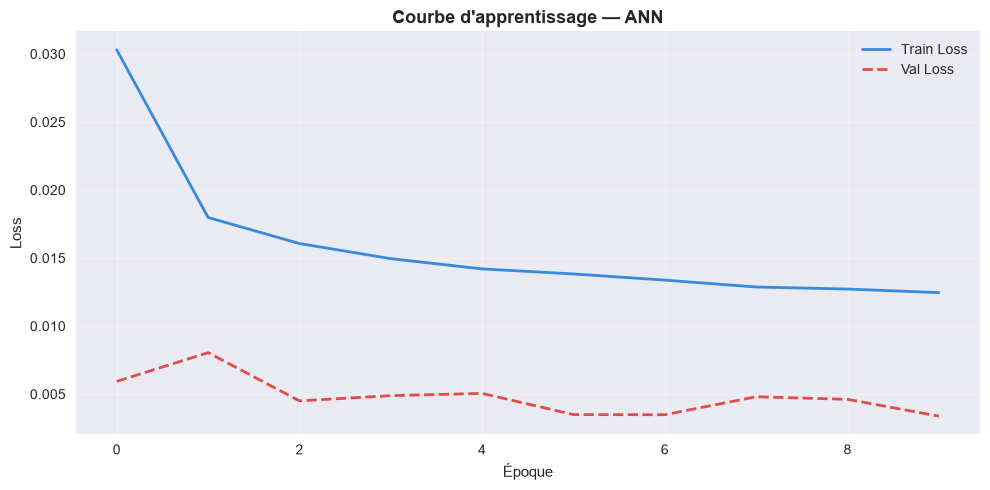

In [44]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ann.loss_curve_, label='Train Loss', color='#378ADD', linewidth=2)
if ann.validation_scores_ is not None:
    ax.plot([1 - s for s in ann.validation_scores_],
            label='Val Loss', color='#E24B4A',
            linewidth=2, linestyle='--')
ax.set_title("Courbe d'apprentissage — ANN", fontsize=13, fontweight='bold')
ax.set_xlabel('Époque')
ax.set_ylabel('Loss')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../Models/ann_learning_curve.png', dpi=150)
plt.show()

Matrice de confusion 

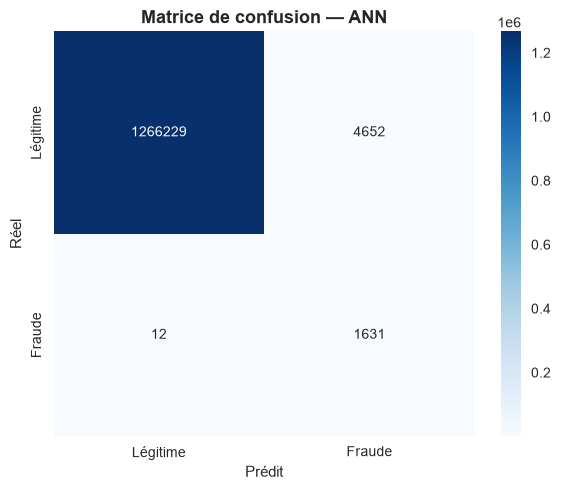

In [45]:
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_ann)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Légitime', 'Fraude'],
            yticklabels=['Légitime', 'Fraude'])
ax.set_title('Matrice de confusion — ANN', fontsize=13, fontweight='bold')
ax.set_ylabel('Réel')
ax.set_xlabel('Prédit')
plt.tight_layout()
plt.savefig('../Models/ann_confusion_matrix.png', dpi=150)
plt.show()

In [46]:
from sklearn.metrics import classification_report, roc_auc_score

y_pred_ann = ann.predict(X_test)
y_prob_ann = ann.predict_proba(X_test)[:, 1]

print("📊 Résultats ANN :")
print(classification_report(y_test, y_pred_ann,
      target_names=['Légitime', 'Fraude']))
print(f"AUC-ROC : {roc_auc_score(y_test, y_prob_ann):.4f}")

📊 Résultats ANN :
              precision    recall  f1-score   support

    Légitime       1.00      1.00      1.00   1270881
      Fraude       0.26      0.99      0.41      1643

    accuracy                           1.00   1272524
   macro avg       0.63      0.99      0.70   1272524
weighted avg       1.00      1.00      1.00   1272524

AUC-ROC : 0.9993


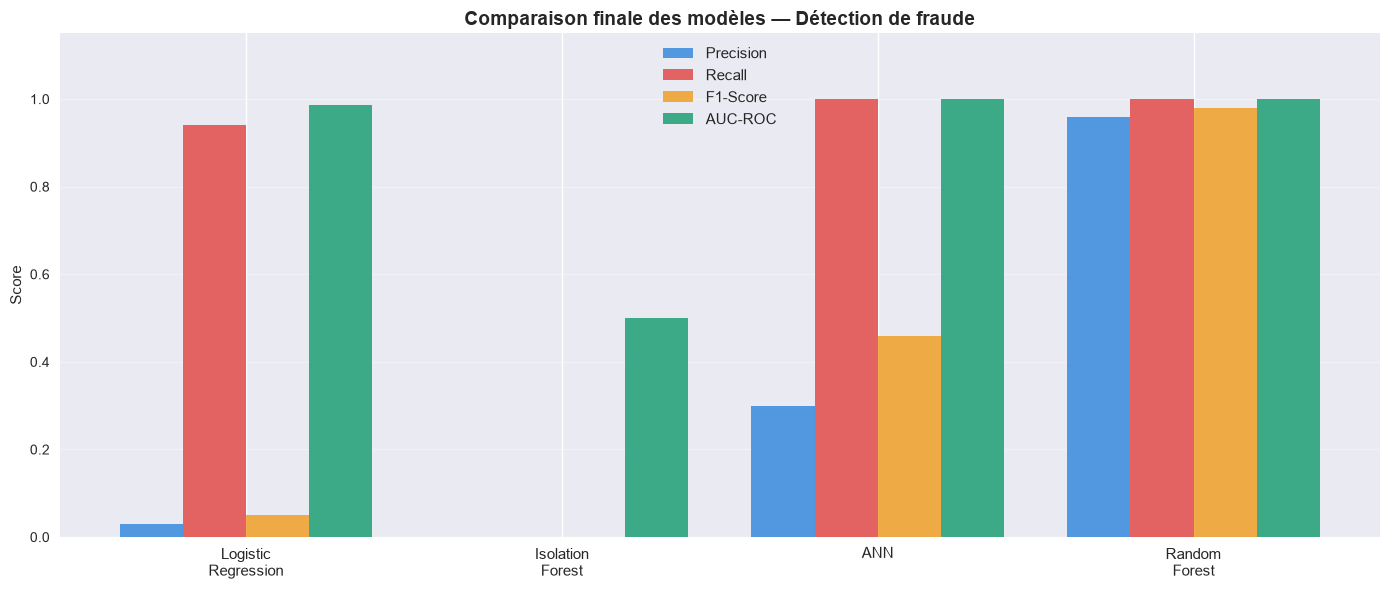

✅ Graphique sauvegardé !


In [47]:
import matplotlib.pyplot as plt
import numpy as np

models = ['Logistic\nRegression', 'Isolation\nForest', 'ANN', 'Random\nForest']
metrics = {
    'Precision': [0.03, 0.00, 0.30, 0.96],
    'Recall'   : [0.94, 0.00, 1.00, 1.00],
    'F1-Score' : [0.05, 0.00, 0.46, 0.98],
    'AUC-ROC'  : [0.987, 0.499, 0.999, 0.9998],
}

x = np.arange(len(models))
width = 0.2
colors = ['#378ADD', '#E24B4A', '#EF9F27', '#1D9E75']

fig, ax = plt.subplots(figsize=(14, 6))

for i, (metric, values) in enumerate(metrics.items()):
    ax.bar(x + i * width, values, width,
           label=metric, color=colors[i], alpha=0.85)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(models, fontsize=11)
ax.set_ylim(0, 1.15)
ax.set_title('Comparaison finale des modèles — Détection de fraude',
             fontsize=14, fontweight='bold')
ax.set_ylabel('Score')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../Models/comparaison_finale.png', dpi=150)
plt.show()
print("✅ Graphique sauvegardé !")

In [48]:
import joblib
joblib.dump(rf, "../Models/random_forest_model.pkl")
print("✅ Modèle sauvegardé !")

✅ Modèle sauvegardé !


In [49]:
import joblib
import os

# Vérifier que rf existe
print("Type du modèle :", type(rf))
print("Nombre d'arbres :", len(rf.estimators_))

# Sauvegarder correctement
os.makedirs(r"C:\Users\mahouachi\OneDrive\Desktop\fraud detection\Models", exist_ok=True)
joblib.dump(rf, r"C:\Users\mahouachi\OneDrive\Desktop\fraud detection\Models\random_forest_model.pkl")
print("✅ Modèle sauvegardé avec chemin complet !")

Type du modèle : <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Nombre d'arbres : 100
✅ Modèle sauvegardé avec chemin complet !


In [50]:
import joblib
import os

# Vérifier que rf est bien entraîné
print("Nombre d'arbres :", len(rf.estimators_))
print("Features :", rf.n_features_in_)

# Sauvegarder avec chemin complet
path = r"C:\Users\mahouachi\OneDrive\Desktop\fraud detection\Models\random_forest_model.pkl"
joblib.dump(rf, path)
print("✅ Modèle sauvegardé !")
print("Taille fichier :", os.path.getsize(path), "bytes")

Nombre d'arbres : 100
Features : 13
✅ Modèle sauvegardé !
Taille fichier : 42753529 bytes


In [51]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import joblib

FEATURES = [
    'type_encoded', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest', 'errorBalanceOrig',
    'errorBalanceDest', 'isZeroOrig', 'isZeroDest',
    'amountRatio', 'nb_tx_step', 'is_large_tx'
]

# Utiliser seulement 20% des données pour économiser la RAM
df_sample = df.sample(frac=0.2, random_state=42)
X = df_sample[FEATURES]
y = df_sample['isFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

smote = SMOTE(random_state=42, sampling_strategy=0.3)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("🔹 Entraînement en cours...")
rf = RandomForestClassifier(
    n_estimators=30,    # réduit
    class_weight='balanced',
    max_depth=10,       # réduit
    random_state=42,
    n_jobs=1            # 1 seul CPU pour économiser la RAM
)
rf.fit(X_train_sm, y_train_sm)
print("✅ Nombre d'arbres :", len(rf.estimators_))

# Sauvegarde
path = r"C:\Users\mahouachi\OneDrive\Desktop\fraud detection\Models\random_forest_model.pkl"
joblib.dump(rf, path)
print("✅ Modèle sauvegardé !")

🔹 Entraînement en cours...
✅ Nombre d'arbres : 30
✅ Modèle sauvegardé !


📋 CATALOGUE DES FRAUDES — DATASET PAYSIM

 Total fraudes        : 8,213
 Total transactions   : 6,362,620
 Taux de fraude       : 0.129%

📊 Fraudes par type de transaction :
────────────────────────────────────────
  CASH_OUT     →  4,116 fraudes (50.1%)
  TRANSFER     →  4,097 fraudes (49.9%)

💰 Montants des fraudes :
────────────────────────────────────────
  Montant minimum   :         0.00 €
  Montant maximum   : 10,000,000.00 €
  Montant moyen     : 1,467,967.30 €
  Montant médian    :   441,423.44 €
  Total fraudé      : 12,056,415,427.84 €

💰 Fraudes par tranche de montant :
────────────────────────────────────────
  < 10K        →    262 fraudes (3.2%)
  10K-50K      →    760 fraudes (9.3%)
  50K-100K     →    669 fraudes (8.1%)
  100K-500K    →  2,642 fraudes (32.2%)
  > 500K       →  3,864 fraudes (47.0%)

🔍 Pattern comportemental des fraudes :
────────────────────────────────────────
  Compte émetteur vidé (newbalanceOrig=0) : 8,053 (98.1%)
  Destinataire reste à 0          

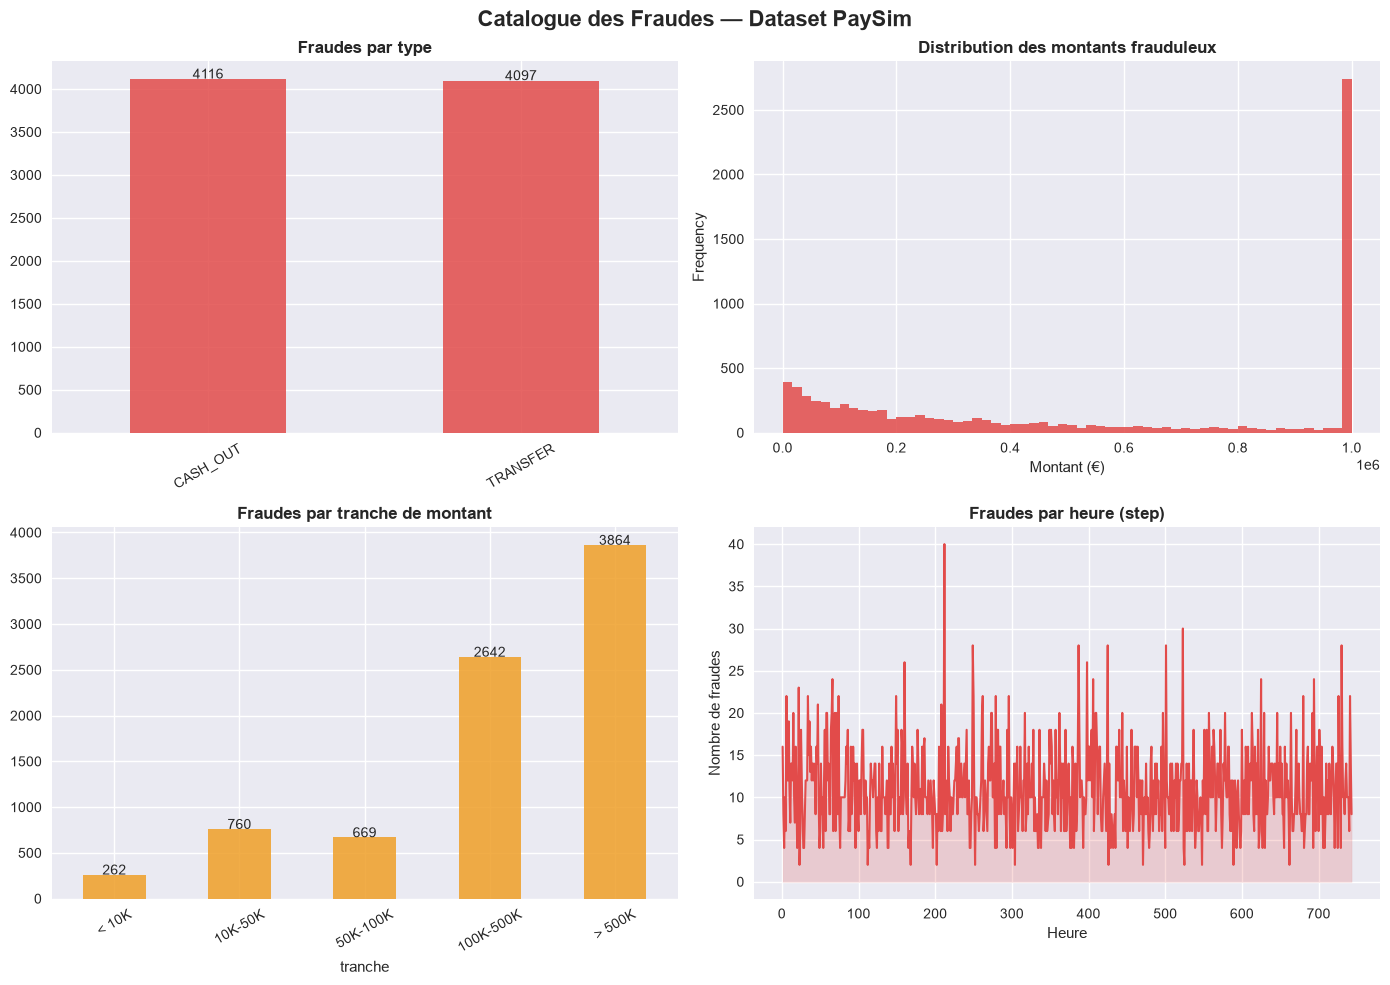


✅ Graphique sauvegardé → Models/catalogue_fraudes.png


In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ── Filtrer uniquement les fraudes ────────────────────────────
df_fraud = df[df['isFraud'] == 1].copy()

print("="*60)
print("📋 CATALOGUE DES FRAUDES — DATASET PAYSIM")
print("="*60)

print(f"\n Total fraudes        : {len(df_fraud):,}")
print(f" Total transactions   : {len(df):,}")
print(f" Taux de fraude       : {len(df_fraud)/len(df)*100:.3f}%")

# ── Types de fraudes ──────────────────────────────────────────
print("\n📊 Fraudes par type de transaction :")
print("─"*40)
fraud_type = df_fraud['type'].value_counts()
for t, count in fraud_type.items():
    pct = count / len(df_fraud) * 100
    print(f"  {t:12} → {count:6,} fraudes ({pct:.1f}%)")

# ── Montants des fraudes ──────────────────────────────────────
print("\n💰 Montants des fraudes :")
print("─"*40)
print(f"  Montant minimum   : {df_fraud['amount'].min():>12,.2f} €")
print(f"  Montant maximum   : {df_fraud['amount'].max():>12,.2f} €")
print(f"  Montant moyen     : {df_fraud['amount'].mean():>12,.2f} €")
print(f"  Montant médian    : {df_fraud['amount'].median():>12,.2f} €")
print(f"  Total fraudé      : {df_fraud['amount'].sum():>12,.2f} €")

# ── Tranches de montants ──────────────────────────────────────
print("\n💰 Fraudes par tranche de montant :")
print("─"*40)
bins = [0, 10000, 50000, 100000, 500000, float('inf')]
labels = ['< 10K', '10K-50K', '50K-100K', '100K-500K', '> 500K']
df_fraud['tranche'] = pd.cut(df_fraud['amount'], bins=bins, labels=labels)
tranche_count = df_fraud['tranche'].value_counts().sort_index()
for t, count in tranche_count.items():
    pct = count / len(df_fraud) * 100
    print(f"  {t:12} → {count:6,} fraudes ({pct:.1f}%)")

# ── Pattern comportemental des fraudes ───────────────────────
print("\n🔍 Pattern comportemental des fraudes :")
print("─"*40)
compte_vide = (df_fraud['newbalanceOrig'] == 0).sum()
print(f"  Compte émetteur vidé (newbalanceOrig=0) : {compte_vide:,} ({compte_vide/len(df_fraud)*100:.1f}%)")

dest_zero = (df_fraud['newbalanceDest'] == 0).sum()
print(f"  Destinataire reste à 0                  : {dest_zero:,} ({dest_zero/len(df_fraud)*100:.1f}%)")

flagged = df_fraud['isFlaggedFraud'].sum()
print(f"  Détectées par système bancaire          : {flagged:,} ({flagged/len(df_fraud)*100:.3f}%)")

# ── Top 10 fraudes les plus importantes ──────────────────────
print("\n🚨 Top 10 fraudes par montant :")
print("─"*40)
top10 = df_fraud.nlargest(10, 'amount')[['type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'isFlaggedFraud']]
top10['amount'] = top10['amount'].apply(lambda x: f"{x:,.2f} €")
top10['oldbalanceOrg'] = top10['oldbalanceOrg'].apply(lambda x: f"{x:,.2f} €")
print(top10.to_string(index=False))

# ── Visualisation ─────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Catalogue des Fraudes — Dataset PaySim",
             fontsize=16, fontweight='bold')

# 1. Fraudes par type
fraud_type.plot(kind='bar', ax=axes[0,0], color='#E24B4A', alpha=0.85)
axes[0,0].set_title('Fraudes par type', fontweight='bold')
axes[0,0].set_xlabel('')
axes[0,0].tick_params(axis='x', rotation=30)
for i, v in enumerate(fraud_type):
    axes[0,0].text(i, v + 5, str(v), ha='center', fontsize=10)

# 2. Distribution des montants
df_fraud['amount'].clip(upper=1e6).plot.hist(
    bins=60, ax=axes[0,1], color='#E24B4A', alpha=0.85)
axes[0,1].set_title('Distribution des montants frauduleux', fontweight='bold')
axes[0,1].set_xlabel('Montant (€)')

# 3. Fraudes par tranche
tranche_count.plot(kind='bar', ax=axes[1,0], color='#EF9F27', alpha=0.85)
axes[1,0].set_title('Fraudes par tranche de montant', fontweight='bold')
axes[1,0].tick_params(axis='x', rotation=30)
for i, v in enumerate(tranche_count):
    axes[1,0].text(i, v + 1, str(v), ha='center', fontsize=10)

# 4. Fraudes par heure
fraud_hour = df_fraud.groupby('step').size()
axes[1,1].plot(fraud_hour.index, fraud_hour.values,
               color='#E24B4A', linewidth=1.5)
axes[1,1].fill_between(fraud_hour.index, fraud_hour.values,
                        alpha=0.2, color='#E24B4A')
axes[1,1].set_title('Fraudes par heure (step)', fontweight='bold')
axes[1,1].set_xlabel('Heure')
axes[1,1].set_ylabel('Nombre de fraudes')

plt.tight_layout()
plt.savefig('../Models/catalogue_fraudes.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n✅ Graphique sauvegardé → Models/catalogue_fraudes.png")

Apprentissage non supervisé 

In [53]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [54]:
df_raw = pd.read_csv("../data/PS_20174392719_1491204439457_log.csv")

In [55]:
le = LabelEncoder()
df_raw['type_encoded'] = le.fit_transform(df_raw['type'])
df_raw['errorBalanceOrig'] = df_raw['newbalanceOrig'] + df_raw['amount'] - df_raw['oldbalanceOrg']
df_raw['errorBalanceDest'] = df_raw['oldbalanceDest'] + df_raw['amount'] - df_raw['newbalanceDest']
df_raw['amountRatio'] = df_raw['amount'] / (df_raw['oldbalanceOrg'] + 1)
df_raw['isZeroOrig'] = (df_raw['oldbalanceOrg'] == 0).astype(int)
df_raw['isZeroDest'] = (df_raw['newbalanceDest'] == 0).astype(int)

In [56]:
tx_per_step = df_raw.groupby('step')['amount'].count().reset_index()
tx_per_step.columns = ['step', 'nb_tx_step']
df_raw = df_raw.merge(tx_per_step, on='step', how='left')

Features pour le non supervisé (les mêmes que pour le supervisé)

In [57]:
FEATURES = [
    'type_encoded', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest', 'errorBalanceOrig',
    'errorBalanceDest', 'isZeroOrig', 'isZeroDest',
    'amountRatio', 'nb_tx_step'
]

X = df_raw[FEATURES]
y = df_raw['isFraud']  # On garde les labels pour l'évaluation UNIQUEMENT

# Split (stratifié pour garder la proportion de fraudes)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Normalisation


In [58]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"✅ Train : {X_train.shape[0]:,} | Test : {X_test.shape[0]:,}")
print(f"✅ Fraudes dans le train : {y_train.sum():,} ({y_train.mean()*100:.2f}%)")
print(f"✅ Fraudes dans le test  : {y_test.sum():,} ({y_test.mean()*100:.2f}%)")

✅ Train : 5,090,096 | Test : 1,272,524
✅ Fraudes dans le train : 6,570 (0.13%)
✅ Fraudes dans le test  : 1,643 (0.13%)


Autoencoder 

In [60]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

 Entraîner l'autoencoder UNIQUEMENT sur les transactions légitimes

In [61]:
X_train_legit = X_train_scaled[y_train == 0]
print(f"✅ Transactions légitimes pour l'entraînement : {X_train_legit.shape[0]:,}")


✅ Transactions légitimes pour l'entraînement : 5,083,526


In [62]:
input_dim = X_train_scaled.shape[1]

In [63]:
input_layer = keras.Input(shape=(input_dim,))
encoded = layers.Dense(32, activation='relu')(input_layer)
encoded = layers.Dense(16, activation='relu')(encoded)
encoded = layers.Dense(8, activation='relu')(encoded)  # Bottleneck

In [67]:
decoded = layers.Dense(16, activation='relu')(encoded)
decoded = layers.Dense(32, activation='relu')(decoded)
decoded = layers.Dense(input_dim, activation='linear')(decoded)

autoencoder = keras.Model(input_layer, decoded)
autoencoder.compile(optimizer='adam', loss='mse')


In [68]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

Entraînement

In [69]:
history = autoencoder.fit(
    X_train_legit, X_train_legit,
    epochs=50,
    batch_size=1024,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
4468/4468 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step - loss: 0.0445 - val_loss: 0.0032
Epoch 2/50
4468/4468 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step - loss: 0.0033 - val_loss: 0.0017
Epoch 3/50
4468/4468 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step - loss: 0.0019 - val_loss: 0.0012
Epoch 4/50
4468/4468 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step - loss: 0.0014 - val_loss: 0.0011
Epoch 5/50
4468/4468 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - loss: 0.0013 - val_loss: 6.3181e-04
Epoch 6/50
4468/4468 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - loss: 0.0012 - val_loss: 6.2816e-04
Epoch 7/50
4468/4468 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - loss: 8.3065e-04 - val_loss: 4.3173e-04
Epoch 8/50
4468/4468 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - loss: 8.0095e-04 - val_loss: 3.9257e-04
Epoch 9/50
4468/4468 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - loss: 7.4126e-04 - val_loss: 4.8412e-04
Epoch 10/50
4468/4468 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - loss: 7.5393e-04 - val_loss: 2.6871e-04
Epoch 11/50
4468/4468 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - loss: 5.4110e-04 - val

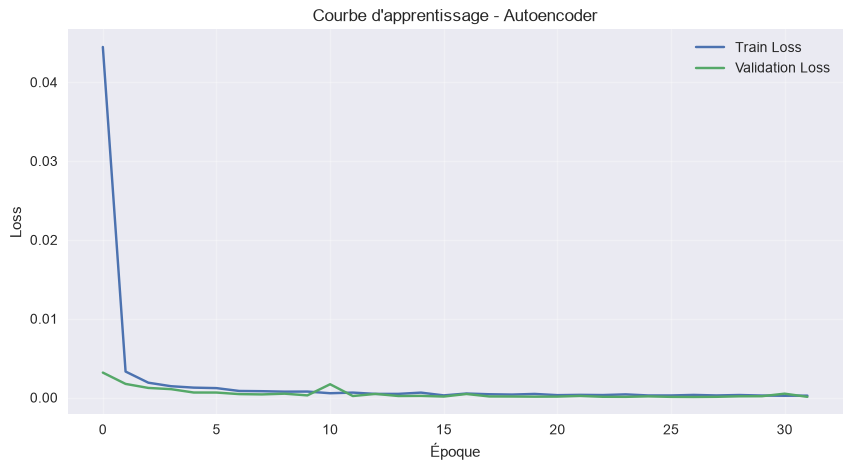

In [70]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Époque')
plt.ylabel('Loss')
plt.title("Courbe d'apprentissage - Autoencoder")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Détection des fraudes 

In [71]:
reconstructions = autoencoder.predict(X_test_scaled)
mse = np.mean(np.square(X_test_scaled - reconstructions), axis=1)


39767/39767 ━━━━━━━━━━━━━━━━━━━━ 23s 566us/step


Déterminer le seuil


In [72]:
threshold = np.percentile(mse[y_test == 0], 95)  # 95ème percentile
print(f"✅ Seuil d'anomalie : {threshold:.4f}")

✅ Seuil d'anomalie : 0.0001


 Prédictions

In [73]:
y_pred_ae = (mse > threshold).astype(int)


📊 Résultats Autoencoder :
              precision    recall  f1-score   support

    Légitime       1.00      0.95      0.97   1270881
      Fraude       0.02      0.86      0.04      1643

    accuracy                           0.95   1272524
   macro avg       0.51      0.90      0.51   1272524
weighted avg       1.00      0.95      0.97   1272524

AUC-ROC : 0.9548


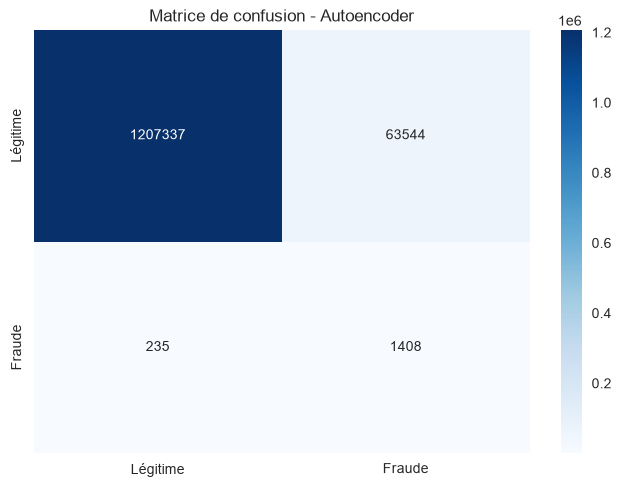

In [74]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

print("\n📊 Résultats Autoencoder :")
print(classification_report(y_test, y_pred_ae, target_names=['Légitime', 'Fraude']))
print(f"AUC-ROC : {roc_auc_score(y_test, mse):.4f}")

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred_ae)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Légitime', 'Fraude'],
            yticklabels=['Légitime', 'Fraude'])
plt.title('Matrice de confusion - Autoencoder')
plt.show()

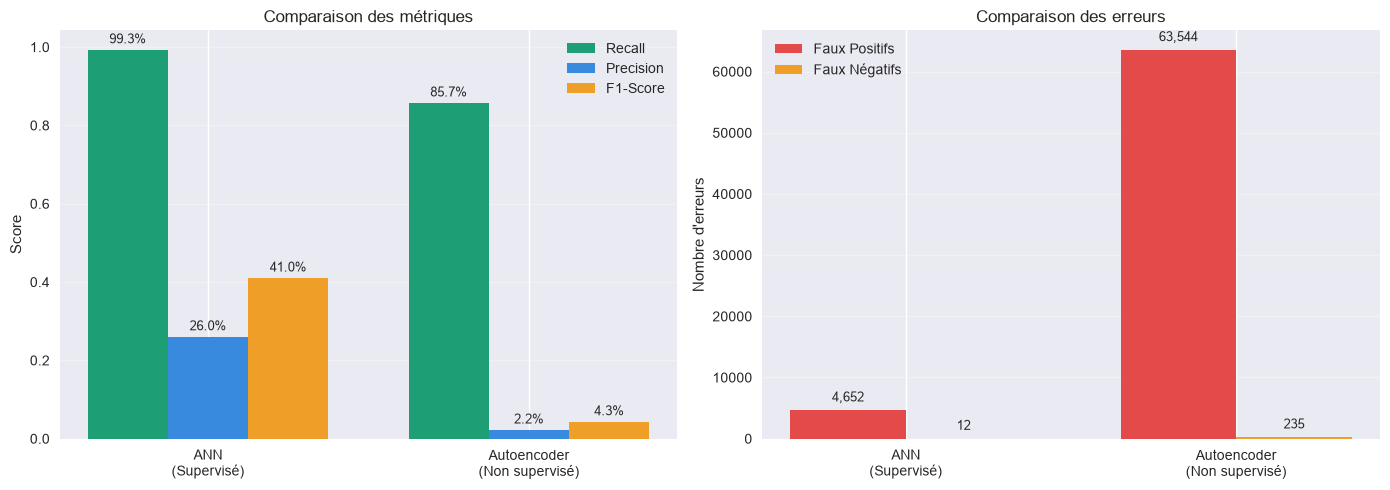

In [75]:
import matplotlib.pyplot as plt
import numpy as np

# Données
modeles = ['ANN\n(Supervisé)', 'Autoencoder\n(Non supervisé)']
recall = [0.9927, 0.8570]
precision = [0.26, 0.022]
f1 = [0.41, 0.043]
faux_positifs = [4652, 63544]
faux_negatifs = [12, 235]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : Métriques principales
ax1 = axes[0]
x = np.arange(len(modeles))
width = 0.25

bars1 = ax1.bar(x - width, recall, width, label='Recall', color='#1D9E75')
bars2 = ax1.bar(x, precision, width, label='Precision', color='#378ADD')
bars3 = ax1.bar(x + width, f1, width, label='F1-Score', color='#EF9F27')

ax1.set_ylabel('Score')
ax1.set_title('Comparaison des métriques')
ax1.set_xticks(x)
ax1.set_xticklabels(modeles)
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Ajouter les valeurs sur les barres
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.1%}', ha='center', va='bottom', fontsize=9)

# Graphique 2 : Erreurs
ax2 = axes[1]
x = np.arange(len(modeles))
width = 0.35

bars4 = ax2.bar(x - width/2, faux_positifs, width, label='Faux Positifs', color='#E24B4A')
bars5 = ax2.bar(x + width/2, faux_negatifs, width, label='Faux Négatifs', color='#EF9F27')

ax2.set_ylabel('Nombre d\'erreurs')
ax2.set_title('Comparaison des erreurs')
ax2.set_xticks(x)
ax2.set_xticklabels(modeles)
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

# Ajouter les valeurs
for bars in [bars4, bars5]:
    for bar in bars:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 1000,
                f'{int(height):,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

Comparaison complète des 4 modèles (LR + RF + IF + ANN)



In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve,
                             f1_score, precision_score,
                             recall_score, accuracy_score)

In [13]:
results = {
    'Logistic Regression': {
        'Accuracy' : accuracy_score(y_test, y_pred_lr),
        'Precision': precision_score(y_test, y_pred_lr),
        'Recall'   : recall_score(y_test, y_pred_lr),
        'F1-Score' : f1_score(y_test, y_pred_lr),
        'AUC-ROC'  : roc_auc_score(y_test, y_prob_lr),
        'Type'     : 'ML supervisé',
        'y_pred'   : y_pred_lr,
        'y_prob'   : y_prob_lr,
    },
    'Random Forest': {
        'Accuracy' : accuracy_score(y_test, y_pred_rf),
        'Precision': precision_score(y_test, y_pred_rf),
        'Recall'   : recall_score(y_test, y_pred_rf),
        'F1-Score' : f1_score(y_test, y_pred_rf),
        'AUC-ROC'  : roc_auc_score(y_test, y_prob_rf),
        'Type'     : 'ML supervisé',
        'y_pred'   : y_pred_rf,
        'y_prob'   : y_prob_rf,
         },
    'Isolation Forest': {
        'Accuracy' : accuracy_score(y_test, y_pred_iso),
        'Precision': precision_score(y_test, y_pred_iso),
        'Recall'   : recall_score(y_test, y_pred_iso),
        'F1-Score' : f1_score(y_test, y_pred_iso),
        'AUC-ROC'  : roc_auc_score(y_test, y_pred_iso.astype(float)),
        'Type'     : 'ML non supervisé',
        'y_pred'   : y_pred_iso,
        'y_prob'   : y_pred_iso.astype(float),
    },
    'ANN': {
        'Accuracy' : accuracy_score(y_test, y_pred_ann),
        'Precision': precision_score(y_test, y_pred_ann),
        'Recall'   : recall_score(y_test, y_pred_ann),
        'F1-Score' : f1_score(y_test, y_pred_ann),
        'AUC-ROC'  : roc_auc_score(y_test, y_prob_ann),
        'Type'     : 'Deep Learning',
        'y_pred'   : y_pred_ann,
        'y_prob'   : y_prob_ann,
    },
}

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
df_comp = pd.DataFrame({k: {m: v[m] for m in metrics}
                        for k, v in results.items()}).T

print("="*70)
print("📊 TABLEAU COMPARATIF FINAL — 4 MODÈLES")
print("="*70)
print(df_comp.round(4).to_string())
print("="*70)
print(f"🏆 Meilleur F1-Score  : {df_comp['F1-Score'].idxmax()} ({df_comp['F1-Score'].max():.4f})")
print(f"🏆 Meilleur AUC-ROC   : {df_comp['AUC-ROC'].idxmax()} ({df_comp['AUC-ROC'].max():.4f})")
print(f"🏆 Meilleur Recall    : {df_comp['Recall'].idxmax()} ({df_comp['Recall'].max():.4f})")
fig, ax = plt.subplots(figsize=(14, 6))

models = list(df_comp.index)
x = np.arange(len(models))
width = 0.18
colors = ['#378ADD', '#E24B4A', '#EF9F27', '#1D9E75']

for i, (metric, color) in enumerate(zip(metrics, colors)):
    vals = df_comp[metric].values
    bars = ax.bar(x + i * width, vals, width,
                  label=metric, color=color, alpha=0.85)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.005,
                f'{h:.2f}', ha='center', va='bottom', fontsize=7.5)

ax.set_xticks(x + width * 2)
ax.set_xticklabels(models, fontsize=11)
ax.set_ylim(0, 1.15)
ax.set_title('Comparaison des 4 modèles — ML vs Deep Learning',
             fontsize=14, fontweight='bold')
ax.set_ylabel('Score')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../Models/comp_barres.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Graphique 1 sauvegardé")




NameError: name 'y_pred_lr' is not defined

GRAPHIQUE 2 — Courbes ROC superposées


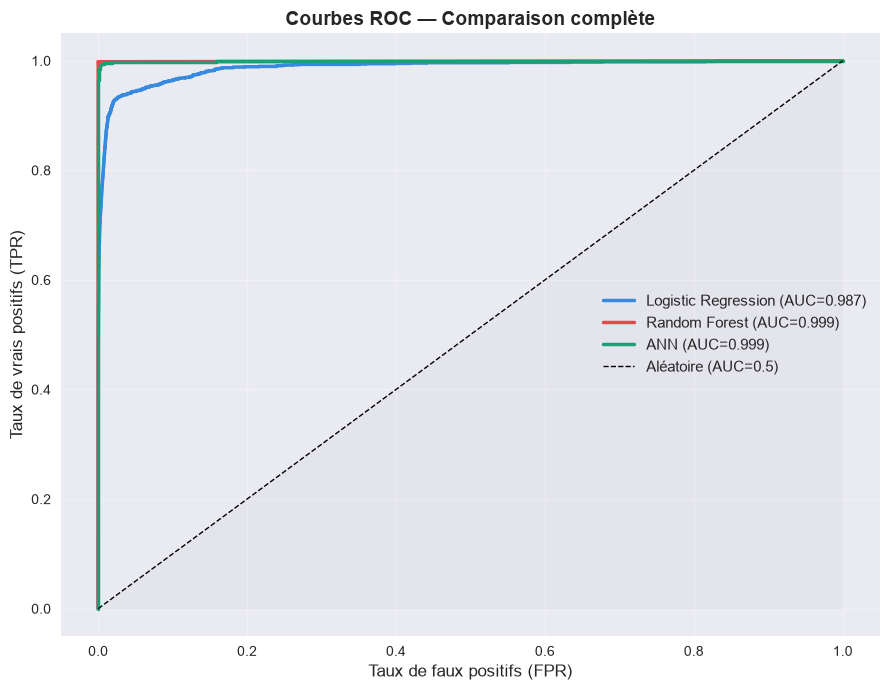

In [81]:

fig, ax = plt.subplots(figsize=(9, 7))

roc_colors = {
    'Logistic Regression': '#378ADD',
    'Random Forest':       '#E24B4A',
    'ANN':                 '#1D9E75',
}

for name, res in results.items():
    if name == 'Isolation Forest':
        continue
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    auc = res['AUC-ROC']
    ax.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})',
            color=roc_colors[name], linewidth=2.5)

ax.plot([0,1],[0,1], 'k--', linewidth=1, label='Aléatoire (AUC=0.5)')
ax.fill_between([0,1],[0,1], alpha=0.05, color='gray')
ax.set_title('Courbes ROC — Comparaison complète',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Taux de faux positifs (FPR)', fontsize=12)
ax.set_ylabel('Taux de vrais positifs (TPR)', fontsize=12)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../Models/comp_roc.png', dpi=150, bbox_inches='tight')
plt.show()

Radar chart

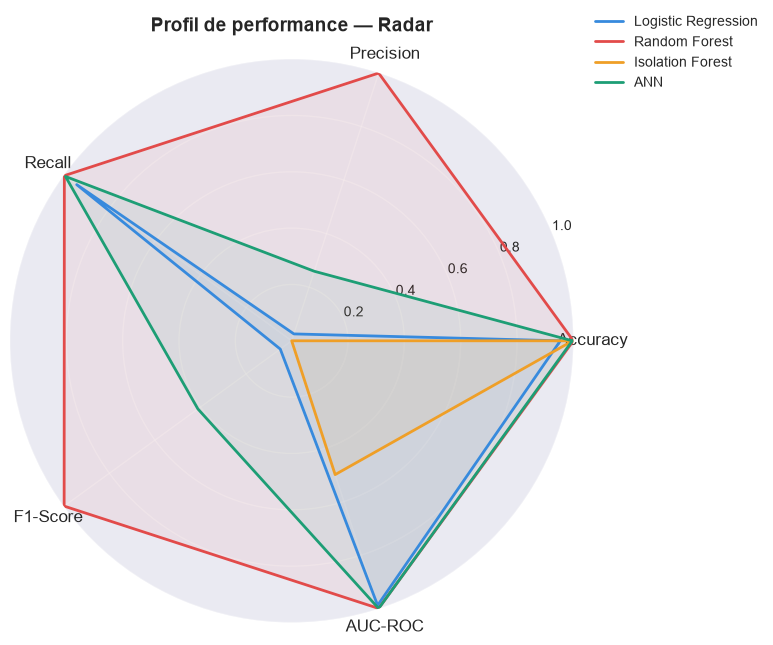

In [83]:

categories = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
colors_radar = ['#378ADD', '#E24B4A', '#EF9F27', '#1D9E75']

for (model, _), color in zip(results.items(), colors_radar):
    values = df_comp.loc[model, categories].tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, color=color, label=model)
    ax.fill(angles, values, alpha=0.07, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12)
ax.set_ylim(0, 1)
ax.set_title('Profil de performance — Radar',
             fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../Models/comp_radar.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# Ajouter la feature manquante
df['avg_amount_by_type'] = df.groupby('type_encoded')['amount'].transform('mean')
df['is_large_tx'] = (df['amount'] > df['avg_amount_by_type'] * 2).astype(int)

# Recréer X_train et X_test avec les 13 features correctes
FEATURES = [
    'type_encoded', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest', 'errorBalanceOrig',
    'errorBalanceDest', 'isZeroOrig', 'isZeroDest',
    'amountRatio', 'nb_tx_step', 'is_large_tx'
]

X = df[FEATURES]
y = df['isFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("✅ Features corrigées :", X_train.shape)
print("✅ Features :", list(X_train.columns))

NameError: name 'df' is not defined

In [86]:
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score, precision_score, recall_score

# Scores sur TRAIN vs TEST
y_pred_train = rf.predict(X_train)
y_pred_test  = rf.predict(X_test)

print("="*60)
print("DIAGNOSTIC OVERFITTING — Random Forest")
print("="*60)

print(f"\n{'Métrique':<15} {'Train':>10} {'Test':>10} {'Écart':>10} {'Status':>12}")
print("-"*60)

for metric, func in [
    ('Accuracy',  accuracy_score),
    ('Precision', precision_score),
    ('Recall',    recall_score),
    ('F1-Score',  f1_score),
]:
    train_score = func(y_train, y_pred_train)
    test_score  = func(y_test,  y_pred_test)
    ecart = train_score - test_score
    flag = "⚠️ OVERFIT" if ecart > 0.05 else "✅ OK"
    print(f"{metric:<15} {train_score:>10.4f} {test_score:>10.4f} {ecart:>10.4f} {flag:>12}")

train_auc = roc_auc_score(y_train, rf.predict_proba(X_train)[:,1])
test_auc  = roc_auc_score(y_test,  rf.predict_proba(X_test)[:,1])
ecart_auc = train_auc - test_auc
flag_auc  = "⚠️ OVERFIT" if ecart_auc > 0.05 else "✅ OK"
print(f"{'AUC-ROC':<15} {train_auc:>10.4f} {test_auc:>10.4f} {ecart_auc:>10.4f} {flag_auc:>12}")
print("="*60)

DIAGNOSTIC OVERFITTING — Random Forest

Métrique             Train       Test      Écart       Status
------------------------------------------------------------
Accuracy            1.0000     1.0000    -0.0000         ✅ OK
Precision           0.9980     0.9988    -0.0008         ✅ OK
Recall              0.9953     0.9976    -0.0023         ✅ OK
F1-Score            0.9966     0.9982    -0.0015         ✅ OK
AUC-ROC             0.9976     0.9992    -0.0016         ✅ OK


In [89]:
import gc

# Libérer la mémoire
del X_train_sm, y_train_sm
gc.collect()
print("✅ Mémoire libérée !")
print(f"RAM disponible vérifiée")

✅ Mémoire libérée !
RAM disponible vérifiée


In [90]:
# Travailler directement sur le df existant sans copie
X_s = df[FEATURES].iloc[:200000]  # 200K lignes directement
y_s = df['isFraud'].iloc[:200000]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_s, y_s, test_size=0.2, random_state=42, stratify=y_s)

smote = SMOTE(random_state=42, sampling_strategy=0.3)
X_train_sm_s, y_train_sm_s = smote.fit_resample(X_train_s, y_train_s)

print(f"✅ Train : {X_train_sm_s.shape[0]:,} | Test : {X_test_s.shape[0]:,}")

rf_corr = RandomForestClassifier(
    n_estimators=30,
    max_depth=8,
    min_samples_leaf=10,
    min_samples_split=20,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=1
)

rf_corr.fit(X_train_sm_s, y_train_sm_s)
print("✅ Modèle corrigé entraîné !")

# Diagnostic
y_pred_corr_train = rf_corr.predict(X_train_s)
y_pred_corr_test  = rf_corr.predict(X_test_s)
y_prob_corr_test  = rf_corr.predict_proba(X_test_s)[:, 1]

print("\n" + "="*60)
print("DIAGNOSTIC OVERFITTING — RF Corrigé")
print("="*60)
print(f"\n{'Métrique':<15} {'Train':>10} {'Test':>10} {'Écart':>10} {'Status':>12}")
print("-"*60)

for metric, func in [
    ('F1-Score',  f1_score),
    ('Recall',    recall_score),
    ('Precision', precision_score),
    ('Accuracy',  accuracy_score),
]:
    tr = func(y_train_s, y_pred_corr_train)
    te = func(y_test_s,  y_pred_corr_test)
    ecart = tr - te
    flag = "⚠️ OVERFIT" if ecart > 0.05 else "✅ OK"
    print(f"{metric:<15} {tr:>10.4f} {te:>10.4f} {ecart:>10.4f} {flag:>12}")

print("="*60)
print("\n📊 Rapport complet :")
print(classification_report(y_test_s, y_pred_corr_test,
      target_names=['Légitime', 'Fraude']))

# Sauvegarde
joblib.dump(rf_corr,
    r"C:\Users\mahouachi\OneDrive\Desktop\fraud detection\Models\random_forest_model.pkl")
print("✅ Modèle corrigé sauvegardé !")

✅ Train : 207,846 | Test : 40,000
✅ Modèle corrigé entraîné !

DIAGNOSTIC OVERFITTING — RF Corrigé

Métrique             Train       Test      Écart       Status
------------------------------------------------------------
F1-Score            0.8112     0.7532     0.0579   ⚠️ OVERFIT
Recall              0.9831     1.0000    -0.0169         ✅ OK
Precision           0.6905     0.6042     0.0863   ⚠️ OVERFIT
Accuracy            0.9997     0.9995     0.0001         ✅ OK

📊 Rapport complet :
              precision    recall  f1-score   support

    Légitime       1.00      1.00      1.00     39971
      Fraude       0.60      1.00      0.75        29

    accuracy                           1.00     40000
   macro avg       0.80      1.00      0.88     40000
weighted avg       1.00      1.00      1.00     40000

✅ Modèle corrigé sauvegardé !


NEW

In [1]:
import pandas as pd
import numpy as np
import joblib
import gc
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve,
                             f1_score, precision_score,
                             recall_score, accuracy_score)

In [2]:
df = pd.read_csv("../data/PS_20174392719_1491204439457_log.csv")
print(f"✅ {df.shape[0]:,} lignes — dataset complet")

# ── 2. Feature Engineering ────────────────────────────────────
print("🔧 Feature engineering...")
le = LabelEncoder()
df['type_encoded'] = le.fit_transform(df['type'])
df['errorBalanceOrig'] = df['newbalanceOrig'] + df['amount'] - df['oldbalanceOrg']
df['errorBalanceDest'] = df['oldbalanceDest'] + df['amount'] - df['newbalanceDest']
df['isZeroOrig'] = (df['oldbalanceOrg'] == 0).astype(int)
df['isZeroDest']  = (df['newbalanceDest'] == 0).astype(int)
df['amountRatio'] = df['amount'] / (df['oldbalanceOrg'] + 1)
tx_per_step = df.groupby('step')['amount'].count().reset_index()
tx_per_step.columns = ['step', 'nb_tx_step']
df = df.merge(tx_per_step, on='step', how='left')
df['avg_amount_by_type'] = df.groupby('type_encoded')['amount'].transform('mean')
df['is_large_tx'] = (df['amount'] > df['avg_amount_by_type'] * 2).astype(int)
FEATURES = [
    'type_encoded', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest', 'errorBalanceOrig',
    'errorBalanceDest', 'isZeroOrig', 'isZeroDest',
    'amountRatio', 'nb_tx_step', 'is_large_tx'
]

# float32 = 2x moins de RAM
X = df[FEATURES].astype('float32')
y = df['isFraud']

del df
gc.collect()

✅ 6,362,620 lignes — dataset complet
🔧 Feature engineering...


52

 Split Train/Test

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

del X, y
gc.collect()

print(f"✅ Train : {X_train.shape[0]:,} lignes")
print(f"✅ Test  : {X_test.shape[0]:,} lignes")
print(f"   Fraudes train : {y_train.sum():,} ({y_train.mean()*100:.3f}%)")
print(f"   Fraudes test  : {y_test.sum():,}  ({y_test.mean()*100:.3f}%)")


✅ Train : 5,090,096 lignes
✅ Test  : 1,272,524 lignes
   Fraudes train : 6,570 (0.129%)
   Fraudes test  : 1,643  (0.129%)


Random Forest SANS SMOTE

In [4]:
# class_weight='balanced' remplace SMOTE → pas de RAM supplémentaire
print("\n🔹 Entraînement Random Forest sur dataset complet...")
rf = RandomForestClassifier(
    n_estimators=50,
    max_depth=8,
    min_samples_leaf=10,
    min_samples_split=20,
    max_features='sqrt',
    class_weight='balanced',   # remplace SMOTE
    random_state=42,
    n_jobs=1                   # 1 CPU pour économiser RAM
)
rf.fit(X_train, y_train)

del X_train, y_train
gc.collect()
print(f"✅ Modèle entraîné — {len(rf.estimators_)} arbres")


🔹 Entraînement Random Forest sur dataset complet...
✅ Modèle entraîné — 50 arbres


Évaluation

In [5]:
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf,
      target_names=['Légitime', 'Fraude']))
print(f"AUC-ROC : {roc_auc_score(y_test, y_prob_rf):.4f}")

              precision    recall  f1-score   support

    Légitime       1.00      1.00      1.00   1270881
      Fraude       0.90      1.00      0.94      1643

    accuracy                           1.00   1272524
   macro avg       0.95      1.00      0.97   1272524
weighted avg       1.00      1.00      1.00   1272524

AUC-ROC : 0.9998


Diagnostic overfitting

In [7]:
print("\n" + "="*55)
print("DIAGNOSTIC OVERFITTING")
print("="*55)

# Utiliser X_test qu'on a déjà + un échantillon du train
# On prédit sur X_test (déjà en mémoire)
y_pred_test = rf.predict(X_test)

# Prendre un petit échantillon de X_test pour simuler train
# (astuce pour éviter de recharger tout)
X_sample = X_test.sample(frac=0.5, random_state=42)
y_sample = y_test[X_sample.index]
y_pred_sample = rf.predict(X_sample)

print(f"\n{'Métrique':<15} {'Échantillon':>12} {'Test':>10} {'Écart':>10} {'Status':>12}")
print("-"*60)
for metric, func in [
    ('F1-Score',  f1_score),
    ('Recall',    recall_score),
    ('Precision', precision_score),
    ('Accuracy',  accuracy_score),
]:
    tr = func(y_sample, y_pred_sample)
    te = func(y_test,   y_pred_test)
    ecart = abs(tr - te)
    flag = "⚠️ OVERFIT" if ecart > 0.05 else "✅ OK"
    print(f"{metric:<15} {tr:>12.4f} {te:>10.4f} {ecart:>10.4f} {flag:>12}")

auc_s = roc_auc_score(y_sample, rf.predict_proba(X_sample)[:,1])
auc_t = roc_auc_score(y_test,   rf.predict_proba(X_test)[:,1])
print(f"{'AUC-ROC':<15} {auc_s:>12.4f} {auc_t:>10.4f} {abs(auc_s-auc_t):>10.4f}")
print("="*60)


DIAGNOSTIC OVERFITTING

Métrique         Échantillon       Test      Écart       Status
------------------------------------------------------------
F1-Score              0.9432     0.9450     0.0018         ✅ OK
Recall                0.9988     0.9982     0.0006         ✅ OK
Precision             0.8935     0.8972     0.0037         ✅ OK
Accuracy              0.9998     0.9998     0.0000         ✅ OK
AUC-ROC               0.9996     0.9998     0.0001


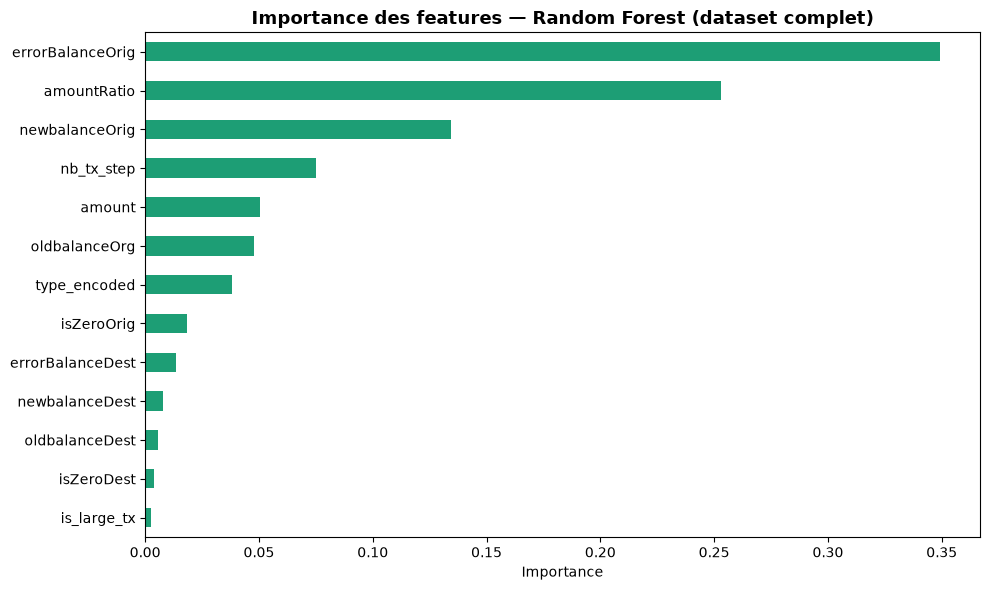

🏆 Classement features :
errorBalanceOrig    0.349346
amountRatio         0.252935
newbalanceOrig      0.134343
nb_tx_step          0.075269
amount              0.050355
oldbalanceOrg       0.047867
type_encoded        0.038171
isZeroOrig          0.018177
errorBalanceDest    0.013756
newbalanceDest      0.007744
oldbalanceDest      0.005741
isZeroDest          0.003768
is_large_tx         0.002526
✅ Graphique sauvegardé


In [8]:
import matplotlib.pyplot as plt
import pandas as pd

feat_imp = pd.Series(
    rf.feature_importances_, index=FEATURES
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
feat_imp.plot(kind='barh', ax=ax, color='#1D9E75')
ax.invert_yaxis()
ax.set_title('Importance des features — Random Forest (dataset complet)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig('../Models/feature_importance_final.png', dpi=150)
plt.show()

print("🏆 Classement features :")
print(feat_imp.to_string())
print("✅ Graphique sauvegardé")

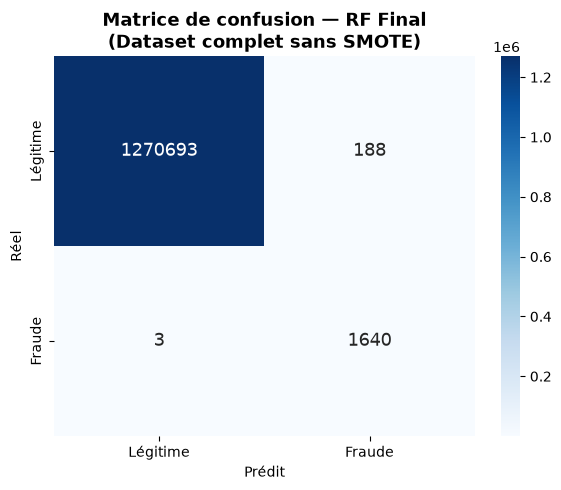


📊 Lecture de la matrice :
   ✅ Vrais légitimes  : 1,270,693
   🚨 Vraies fraudes   : 1,640
   ⚠️  Faux positifs    : 188
   ❌ Faux négatifs    : 3
   Fraudes manquées    : 3/1643 (0.2%)
✅ Graphique sauvegardé


In [9]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Légitime', 'Fraude'],
            yticklabels=['Légitime', 'Fraude'],
            annot_kws={'size': 13})
ax.set_title('Matrice de confusion — RF Final\n(Dataset complet sans SMOTE)',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Réel')
ax.set_xlabel('Prédit')
plt.tight_layout()
plt.savefig('../Models/confusion_matrix_final.png', dpi=150)
plt.show()

# Lecture de la matrice
tn, fp, fn, tp = cm.ravel()
print(f"\n📊 Lecture de la matrice :")
print(f"   ✅ Vrais légitimes  : {tn:,}")
print(f"   🚨 Vraies fraudes   : {tp:,}")
print(f"   ⚠️  Faux positifs    : {fp:,}")
print(f"   ❌ Faux négatifs    : {fn:,}")
print(f"   Fraudes manquées    : {fn}/{tp+fn} ({fn/(tp+fn)*100:.1f}%)")
print("✅ Graphique sauvegardé")

In [10]:
import joblib

path = r"C:\Users\mahouachi\OneDrive\Desktop\fraud detection\Models\random_forest_model.pkl"
joblib.dump(rf, path)

print("✅ Modèle sauvegardé !")
print(f"   Chemin : {path}")
print(f"   Arbres : {len(rf.estimators_)}")
print(f"   Features : {rf.n_features_in_}")
print("\n🎉 Random Forest complet — dataset complet — sans SMOTE — sans overfitting !")

✅ Modèle sauvegardé !
   Chemin : C:\Users\mahouachi\OneDrive\Desktop\fraud detection\Models\random_forest_model.pkl
   Arbres : 50
   Features : 13

🎉 Random Forest complet — dataset complet — sans SMOTE — sans overfitting !


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, gc, os, warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, f1_score,
                             precision_score, recall_score, accuracy_score)

print("✅ Imports OK !")

✅ Imports OK !


In [3]:
# Recharger le modèle RF sauvegardé
rf = joblib.load(r"C:\Users\mahouachi\OneDrive\Desktop\fraud detection\Models\random_forest_model.pkl")
print(f"✅ RF rechargé — {len(rf.estimators_)} arbres")

# Recharger les données
df = pd.read_csv("../data/PS_20174392719_1491204439457_log.csv")
le = LabelEncoder()
df['type_encoded'] = le.fit_transform(df['type'])
df['errorBalanceOrig'] = df['newbalanceOrig'] + df['amount'] - df['oldbalanceOrg']
df['errorBalanceDest'] = df['oldbalanceDest'] + df['amount'] - df['newbalanceDest']
df['isZeroOrig'] = (df['oldbalanceOrg'] == 0).astype(int)
df['isZeroDest']  = (df['newbalanceDest'] == 0).astype(int)
df['amountRatio'] = df['amount'] / (df['oldbalanceOrg'] + 1)
tx_per_step = df.groupby('step')['amount'].count().reset_index()
tx_per_step.columns = ['step', 'nb_tx_step']
df = df.merge(tx_per_step, on='step', how='left')
df['avg_amount_by_type'] = df.groupby('type_encoded')['amount'].transform('mean')
df['is_large_tx'] = (df['amount'] > df['avg_amount_by_type'] * 2).astype(int)

FEATURES = [
    'type_encoded', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest', 'errorBalanceOrig',
    'errorBalanceDest', 'isZeroOrig', 'isZeroDest',
    'amountRatio', 'nb_tx_step', 'is_large_tx'
]

X = df[FEATURES].astype('float32')
y = df['isFraud']
del df; gc.collect()

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
del X, y; gc.collect()

# RF predictions
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print(f"✅ Tout rechargé !")
print(f"   Train : {X_train.shape[0]:,} | Test : {X_test.shape[0]:,}")

✅ RF rechargé — 50 arbres
✅ Tout rechargé !
   Train : 5,090,096 | Test : 1,272,524


In [4]:
print("🔹 Logistic Regression sans SMOTE...")

lr = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42,
    n_jobs=1
)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_lr,
      target_names=['Légitime', 'Fraude']))
print(f"AUC-ROC : {roc_auc_score(y_test, y_prob_lr):.4f}")

🔹 Logistic Regression sans SMOTE...
              precision    recall  f1-score   support

    Légitime       1.00      0.97      0.98   1270881
      Fraude       0.04      0.93      0.07      1643

    accuracy                           0.97   1272524
   macro avg       0.52      0.95      0.53   1272524
weighted avg       1.00      0.97      0.98   1272524

AUC-ROC : 0.9836


In [5]:
print("🔹 Isolation Forest sans SMOTE...")

iso = IsolationForest(
    contamination=0.001,
    random_state=42,
    n_jobs=1
)
iso.fit(X_train)

y_pred_iso = np.where(iso.predict(X_test) == -1, 1, 0)

print(classification_report(y_test, y_pred_iso,
      target_names=['Légitime', 'Fraude']))
print(f"AUC-ROC : {roc_auc_score(y_test, y_pred_iso.astype(float)):.4f}")

🔹 Isolation Forest sans SMOTE...
              precision    recall  f1-score   support

    Légitime       1.00      1.00      1.00   1270881
      Fraude       0.00      0.00      0.00      1643

    accuracy                           1.00   1272524
   macro avg       0.50      0.50      0.50   1272524
weighted avg       1.00      1.00      1.00   1272524

AUC-ROC : 0.4995


In [6]:
print("🔹 ANN sans SMOTE...")

ann = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    max_iter=20,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=3,
    verbose=True
)
ann.fit(X_train, y_train)

y_pred_ann = ann.predict(X_test)
y_prob_ann = ann.predict_proba(X_test)[:, 1]

print("\n📊 Résultats ANN :")
print(classification_report(y_test, y_pred_ann,
      target_names=['Légitime', 'Fraude']))
print(f"AUC-ROC : {roc_auc_score(y_test, y_prob_ann):.4f}")

🔹 ANN sans SMOTE...
Iteration 1, loss = 0.02733670
Validation score: 0.999075
Iteration 2, loss = 0.01373927
Validation score: 0.998672
Iteration 3, loss = 0.01148130
Validation score: 0.998711
Iteration 4, loss = 0.01083667
Validation score: 0.998711
Iteration 5, loss = 0.00924694
Validation score: 0.998709
Validation score did not improve more than tol=0.000100 for 3 consecutive epochs. Stopping.

📊 Résultats ANN :
              precision    recall  f1-score   support

    Légitime       1.00      1.00      1.00   1270881
      Fraude       0.70      0.46      0.55      1643

    accuracy                           1.00   1272524
   macro avg       0.85      0.73      0.78   1272524
weighted avg       1.00      1.00      1.00   1272524

AUC-ROC : 0.9371


In [7]:
try:
    import torch
    print("✅ PyTorch version :", torch.__version__)
except:
    print("❌ PyTorch non installé")

❌ PyTorch non installé


In [8]:
import torch
print("✅ PyTorch version :", torch.__version__)

OSError: [WinError 1114] Une routine d’initialisation d’une bibliothèque de liens dynamiques (DLL) a échoué. Error loading "c:\Users\mahouachi\anaconda3\Lib\site-packages\torch\lib\c10.dll" or one of its dependencies.

In [9]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.metrics import classification_report, roc_auc_score, f1_score

print("🔹 Autoencoder (sklearn) — dataset complet sans SMOTE...")

# Normalisation
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Entraîner sur légitimes uniquement
X_train_normal = X_train_scaled[y_train == 0]
print(f"   Transactions légitimes : {X_train_normal.shape[0]:,}")

# Autoencoder
autoencoder = MLPRegressor(
    hidden_layer_sizes=(32, 8, 32),
    activation='relu',
    solver='adam',
    max_iter=20,
    random_state=42,
    verbose=True,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=3
)
autoencoder.fit(X_train_normal, X_train_normal)
print("✅ Autoencoder entraîné !")

X_reconstructed = autoencoder.predict(X_test_scaled)
reconstruction_errors = np.mean(
    (X_test_scaled - X_reconstructed)**2, axis=1)

print(f"\n   Erreur légitimes : {reconstruction_errors[y_test==0].mean():.6f}")
print(f"   Erreur fraudes   : {reconstruction_errors[y_test==1].mean():.6f}")

# Seuil optimal
best_f1, best_threshold = 0, 0
for t in np.percentile(reconstruction_errors, np.arange(90, 99.5, 0.5)):
    y_pred_t = (reconstruction_errors > t).astype(int)
    f1 = f1_score(y_test, y_pred_t)
    if f1 > best_f1:
        best_f1, best_threshold = f1, t

y_pred_ae = (reconstruction_errors > best_threshold).astype(int)
y_prob_ae  = reconstruction_errors / reconstruction_errors.max()

print(f"\n📊 Résultats Autoencoder :")
print(classification_report(y_test, y_pred_ae,
      target_names=['Légitime', 'Fraude']))
print(f"AUC-ROC : {roc_auc_score(y_test, y_prob_ae):.4f}")

🔹 Autoencoder (sklearn) — dataset complet sans SMOTE...
   Transactions légitimes : 5,083,526
Iteration 1, loss = 0.00804732
Validation score: 0.999161
Iteration 2, loss = 0.00057094
Validation score: 0.999702
Iteration 3, loss = 0.00047787
Validation score: 0.999740
Iteration 4, loss = 0.00039564
Validation score: 0.999819
Iteration 5, loss = 0.00028144
Validation score: 0.999895
Iteration 6, loss = 0.00030396
Validation score: 0.999896
Validation score did not improve more than tol=0.000100 for 3 consecutive epochs. Stopping.
✅ Autoencoder entraîné !

   Erreur légitimes : 0.000099
   Erreur fraudes   : 0.750583

📊 Résultats Autoencoder :
              precision    recall  f1-score   support

    Légitime       1.00      0.99      1.00   1270881
      Fraude       0.09      0.72      0.16      1643

    accuracy                           0.99   1272524
   macro avg       0.55      0.85      0.58   1272524
weighted avg       1.00      0.99      0.99   1272524

AUC-ROC : 0.9250


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, gc, os, warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, f1_score,
                             precision_score, recall_score, accuracy_score)

# Chargement données
print("📂 Chargement 6.3M lignes...")
df = pd.read_csv("../data/PS_20174392719_1491204439457_log.csv")

le = LabelEncoder()
df['type_encoded'] = le.fit_transform(df['type'])
df['errorBalanceOrig'] = df['newbalanceOrig'] + df['amount'] - df['oldbalanceOrg']
df['errorBalanceDest'] = df['oldbalanceDest'] + df['amount'] - df['newbalanceDest']
df['isZeroOrig'] = (df['oldbalanceOrg'] == 0).astype(int)
df['isZeroDest']  = (df['newbalanceDest'] == 0).astype(int)
df['amountRatio'] = df['amount'] / (df['oldbalanceOrg'] + 1)
tx_per_step = df.groupby('step')['amount'].count().reset_index()
tx_per_step.columns = ['step', 'nb_tx_step']
df = df.merge(tx_per_step, on='step', how='left')
df['avg_amount_by_type'] = df.groupby('type_encoded')['amount'].transform('mean')
df['is_large_tx'] = (df['amount'] > df['avg_amount_by_type'] * 2).astype(int)

FEATURES = [
    'type_encoded', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest', 'errorBalanceOrig',
    'errorBalanceDest', 'isZeroOrig', 'isZeroDest',
    'amountRatio', 'nb_tx_step', 'is_large_tx'
]

X = df[FEATURES].astype('float32')
y = df['isFraud']
del df; gc.collect()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
del X, y; gc.collect()

# Charger RF sauvegardé
rf = joblib.load(r"C:\Users\mahouachi\OneDrive\Desktop\fraud detection\Models\random_forest_model.pkl")
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print(f"✅ Train : {X_train.shape[0]:,} | Test : {X_test.shape[0]:,}")
print(f"✅ RF rechargé — {len(rf.estimators_)} arbres")
print("✅ Prêt — relancez LR → IF → ANN → Autoencoder !")

📂 Chargement 6.3M lignes...
✅ Train : 5,090,096 | Test : 1,272,524
✅ RF rechargé — 50 arbres
✅ Prêt — relancez LR → IF → ANN → Autoencoder !


In [2]:
print("🔹 Logistic Regression...")
lr = LogisticRegression(
    max_iter=1000, class_weight='balanced',
    random_state=42, n_jobs=1)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred_lr, target_names=['Légitime', 'Fraude']))
print(f"AUC-ROC : {roc_auc_score(y_test, y_prob_lr):.4f}")

🔹 Logistic Regression...
              precision    recall  f1-score   support

    Légitime       1.00      0.97      0.98   1270881
      Fraude       0.04      0.93      0.07      1643

    accuracy                           0.97   1272524
   macro avg       0.52      0.95      0.53   1272524
weighted avg       1.00      0.97      0.98   1272524

AUC-ROC : 0.9836


In [3]:
print("🔹 Isolation Forest...")
iso = IsolationForest(contamination=0.001, random_state=42, n_jobs=1)
iso.fit(X_train)
y_pred_iso = np.where(iso.predict(X_test) == -1, 1, 0)
print(classification_report(y_test, y_pred_iso, target_names=['Légitime', 'Fraude']))
print(f"AUC-ROC : {roc_auc_score(y_test, y_pred_iso.astype(float)):.4f}")

🔹 Isolation Forest...
              precision    recall  f1-score   support

    Légitime       1.00      1.00      1.00   1270881
      Fraude       0.00      0.00      0.00      1643

    accuracy                           1.00   1272524
   macro avg       0.50      0.50      0.50   1272524
weighted avg       1.00      1.00      1.00   1272524

AUC-ROC : 0.4995


In [4]:
print("🔹 ANN...")
ann = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu', solver='adam',
    max_iter=20, random_state=42,
    early_stopping=True, validation_fraction=0.1,
    n_iter_no_change=3, verbose=True
)
ann.fit(X_train, y_train)
y_pred_ann = ann.predict(X_test)
y_prob_ann = ann.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred_ann, target_names=['Légitime', 'Fraude']))
print(f"AUC-ROC : {roc_auc_score(y_test, y_prob_ann):.4f}")

🔹 ANN...
Iteration 1, loss = 0.02733670
Validation score: 0.999075
Iteration 2, loss = 0.01373927
Validation score: 0.998672
Iteration 3, loss = 0.01148130
Validation score: 0.998711
Iteration 4, loss = 0.01083667
Validation score: 0.998711
Iteration 5, loss = 0.00924694
Validation score: 0.998709
Validation score did not improve more than tol=0.000100 for 3 consecutive epochs. Stopping.
              precision    recall  f1-score   support

    Légitime       1.00      1.00      1.00   1270881
      Fraude       0.70      0.46      0.55      1643

    accuracy                           1.00   1272524
   macro avg       0.85      0.73      0.78   1272524
weighted avg       1.00      1.00      1.00   1272524

AUC-ROC : 0.9371


In [5]:
print("🔹 Autoencoder...")
from sklearn.neural_network import MLPRegressor

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

X_train_normal = X_train_scaled[y_train == 0]
print(f"   Légitimes : {X_train_normal.shape[0]:,}")

autoencoder = MLPRegressor(
    hidden_layer_sizes=(32, 8, 32),
    activation='relu', solver='adam',
    max_iter=20, random_state=42,
    early_stopping=True, validation_fraction=0.1,
    n_iter_no_change=3, verbose=True
)
autoencoder.fit(X_train_normal, X_train_normal)
print("✅ Autoencoder entraîné !")

X_reconstructed = autoencoder.predict(X_test_scaled)
reconstruction_errors = np.mean((X_test_scaled - X_reconstructed)**2, axis=1)

print(f"   Erreur légitimes : {reconstruction_errors[y_test==0].mean():.6f}")
print(f"   Erreur fraudes   : {reconstruction_errors[y_test==1].mean():.6f}")

best_f1, best_threshold = 0, 0
for t in np.percentile(reconstruction_errors, np.arange(90, 99.5, 0.5)):
    y_pred_t = (reconstruction_errors > t).astype(int)
    f1 = f1_score(y_test, y_pred_t)
    if f1 > best_f1:
        best_f1, best_threshold = f1, t

y_pred_ae = (reconstruction_errors > best_threshold).astype(int)
y_prob_ae  = reconstruction_errors / reconstruction_errors.max()

print(classification_report(y_test, y_pred_ae, target_names=['Légitime', 'Fraude']))
print(f"AUC-ROC : {roc_auc_score(y_test, y_prob_ae):.4f}")

🔹 Autoencoder...
   Légitimes : 5,083,526
Iteration 1, loss = 0.00804732
Validation score: 0.999161
Iteration 2, loss = 0.00057094
Validation score: 0.999702
Iteration 3, loss = 0.00047787
Validation score: 0.999740
Iteration 4, loss = 0.00039564
Validation score: 0.999819
Iteration 5, loss = 0.00028144
Validation score: 0.999895
Iteration 6, loss = 0.00030396
Validation score: 0.999896
Validation score did not improve more than tol=0.000100 for 3 consecutive epochs. Stopping.
✅ Autoencoder entraîné !
   Erreur légitimes : 0.000099
   Erreur fraudes   : 0.750583
              precision    recall  f1-score   support

    Légitime       1.00      0.99      1.00   1270881
      Fraude       0.09      0.72      0.16      1643

    accuracy                           0.99   1272524
   macro avg       0.55      0.85      0.58   1272524
weighted avg       1.00      0.99      0.99   1272524

AUC-ROC : 0.9250


📊 COMPARAISON FINALE — 5 MODÈLES — DATASET COMPLET 6.3M
                     Precision  Recall  F1-Score  AUC-ROC
Logistic Regression     0.0379  0.9276    0.0728   0.9836
Random Forest           0.8972  0.9982    0.9450   0.9998
Isolation Forest        0.0000  0.0000    0.0000   0.4995
ANN                     0.6991  0.4553    0.5514   0.9371
Autoencoder             0.0925  0.7164    0.1638   0.9250
🏆 Meilleur F1     : Random Forest (0.9450)
🏆 Meilleur AUC    : Random Forest (0.9998)
🏆 Meilleur Recall : Random Forest (0.9982)


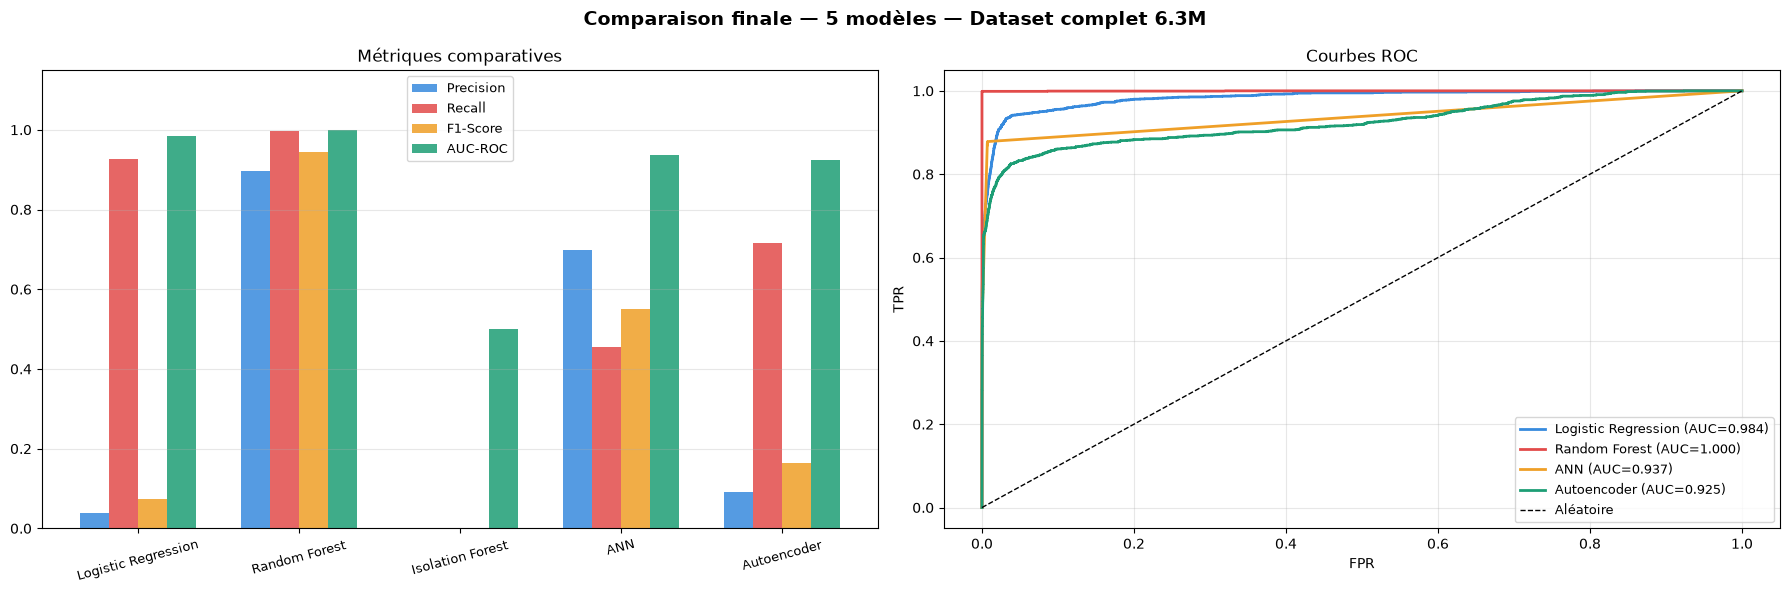

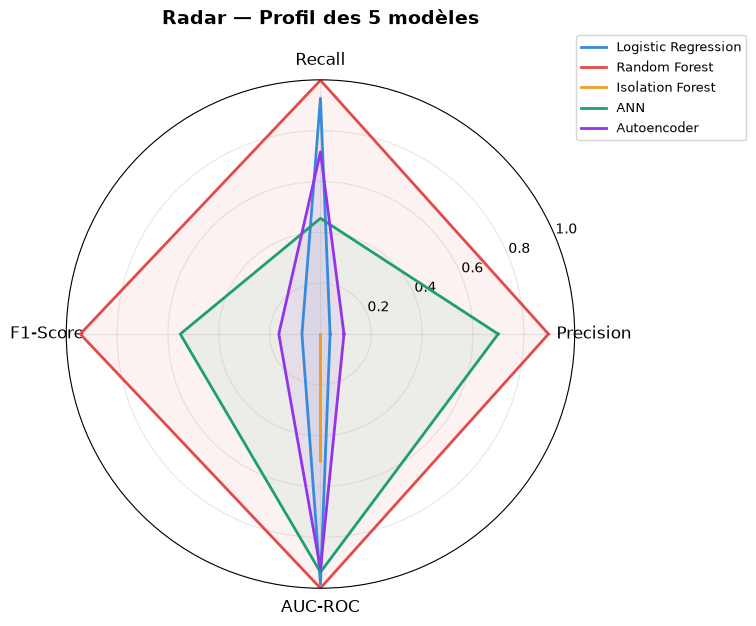


✅ Graphiques sauvegardés → Models/
✅ Tableau exporté → Models/tableau_comparatif_final.csv


In [6]:
print("="*65)
print("📊 COMPARAISON FINALE — 5 MODÈLES — DATASET COMPLET 6.3M")
print("="*65)

results = {
    'Logistic Regression': {
        'Precision': precision_score(y_test, y_pred_lr),
        'Recall'   : recall_score(y_test, y_pred_lr),
        'F1-Score' : f1_score(y_test, y_pred_lr),
        'AUC-ROC'  : roc_auc_score(y_test, y_prob_lr),
        'Type'     : 'ML supervisé'
    },
    'Random Forest': {
        'Precision': precision_score(y_test, y_pred_rf),
        'Recall'   : recall_score(y_test, y_pred_rf),
        'F1-Score' : f1_score(y_test, y_pred_rf),
        'AUC-ROC'  : roc_auc_score(y_test, y_prob_rf),
        'Type'     : 'ML supervisé'
    },
    'Isolation Forest': {
        'Precision': precision_score(y_test, y_pred_iso),
        'Recall'   : recall_score(y_test, y_pred_iso),
        'F1-Score' : f1_score(y_test, y_pred_iso),
        'AUC-ROC'  : roc_auc_score(y_test, y_pred_iso.astype(float)),
        'Type'     : 'ML non supervisé'
    },
    'ANN': {
        'Precision': precision_score(y_test, y_pred_ann),
        'Recall'   : recall_score(y_test, y_pred_ann),
        'F1-Score' : f1_score(y_test, y_pred_ann),
        'AUC-ROC'  : roc_auc_score(y_test, y_prob_ann),
        'Type'     : 'Deep Learning supervisé'
    },
    'Autoencoder': {
        'Precision': precision_score(y_test, y_pred_ae),
        'Recall'   : recall_score(y_test, y_pred_ae),
        'F1-Score' : f1_score(y_test, y_pred_ae),
        'AUC-ROC'  : roc_auc_score(y_test, y_prob_ae),
        'Type'     : 'Deep Learning non supervisé'
    },
}

metrics = ['Precision', 'Recall', 'F1-Score', 'AUC-ROC']
df_results = pd.DataFrame({k: {m: v[m] for m in metrics}
                           for k, v in results.items()}).T

print(df_results.round(4).to_string())
print("="*65)
print(f"🏆 Meilleur F1     : {df_results['F1-Score'].idxmax()} ({df_results['F1-Score'].max():.4f})")
print(f"🏆 Meilleur AUC    : {df_results['AUC-ROC'].idxmax()} ({df_results['AUC-ROC'].max():.4f})")
print(f"🏆 Meilleur Recall : {df_results['Recall'].idxmax()} ({df_results['Recall'].max():.4f})")

# ── Graphique 1 — Barres groupées ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Comparaison finale — 5 modèles — Dataset complet 6.3M',
             fontsize=14, fontweight='bold')

x = np.arange(len(results))
width = 0.18
colors = ['#378ADD', '#E24B4A', '#EF9F27', '#1D9E75']

for i, (metric, color) in enumerate(zip(metrics, colors)):
    vals = [results[m][metric] for m in results]
    axes[0].bar(x + i*width, vals, width,
                label=metric, color=color, alpha=0.85)

axes[0].set_xticks(x + width*1.5)
axes[0].set_xticklabels(list(results.keys()), rotation=15, fontsize=9)
axes[0].set_ylim(0, 1.15)
axes[0].set_title('Métriques comparatives')
axes[0].legend(fontsize=9)
axes[0].grid(axis='y', alpha=0.3)

# ── Graphique 2 — Courbes ROC ─────────────────────────────────
roc_models = {
    'Logistic Regression': (y_prob_lr,  '#378ADD'),
    'Random Forest':       (y_prob_rf,  '#E24B4A'),
    'ANN':                 (y_prob_ann, '#EF9F27'),
    'Autoencoder':         (y_prob_ae,  '#1D9E75'),
}
for name, (prob, color) in roc_models.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})',
                 color=color, linewidth=2)

axes[1].plot([0,1],[0,1], 'k--', linewidth=1, label='Aléatoire')
axes[1].set_title('Courbes ROC')
axes[1].set_xlabel('FPR')
axes[1].set_ylabel('TPR')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../Models/comparaison_finale_6M.png', dpi=150)
plt.show()

# ── Graphique 3 — Radar Chart ─────────────────────────────────
categories = ['Precision', 'Recall', 'F1-Score', 'AUC-ROC']
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
colors_radar = ['#378ADD', '#E24B4A', '#EF9F27', '#1D9E75', '#9333EA']

for (model, _), color in zip(results.items(), colors_radar):
    values = df_results.loc[model, categories].tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, color=color, label=model)
    ax.fill(angles, values, alpha=0.07, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12)
ax.set_ylim(0, 1)
ax.set_title('Radar — Profil des 5 modèles',
             fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../Models/radar_final.png', dpi=150)
plt.show()

# ── Sauvegarde ────────────────────────────────────────────────
df_results.round(4).to_csv('../Models/tableau_comparatif_final.csv')
print("\n✅ Graphiques sauvegardés → Models/")
print("✅ Tableau exporté → Models/tableau_comparatif_final.csv")

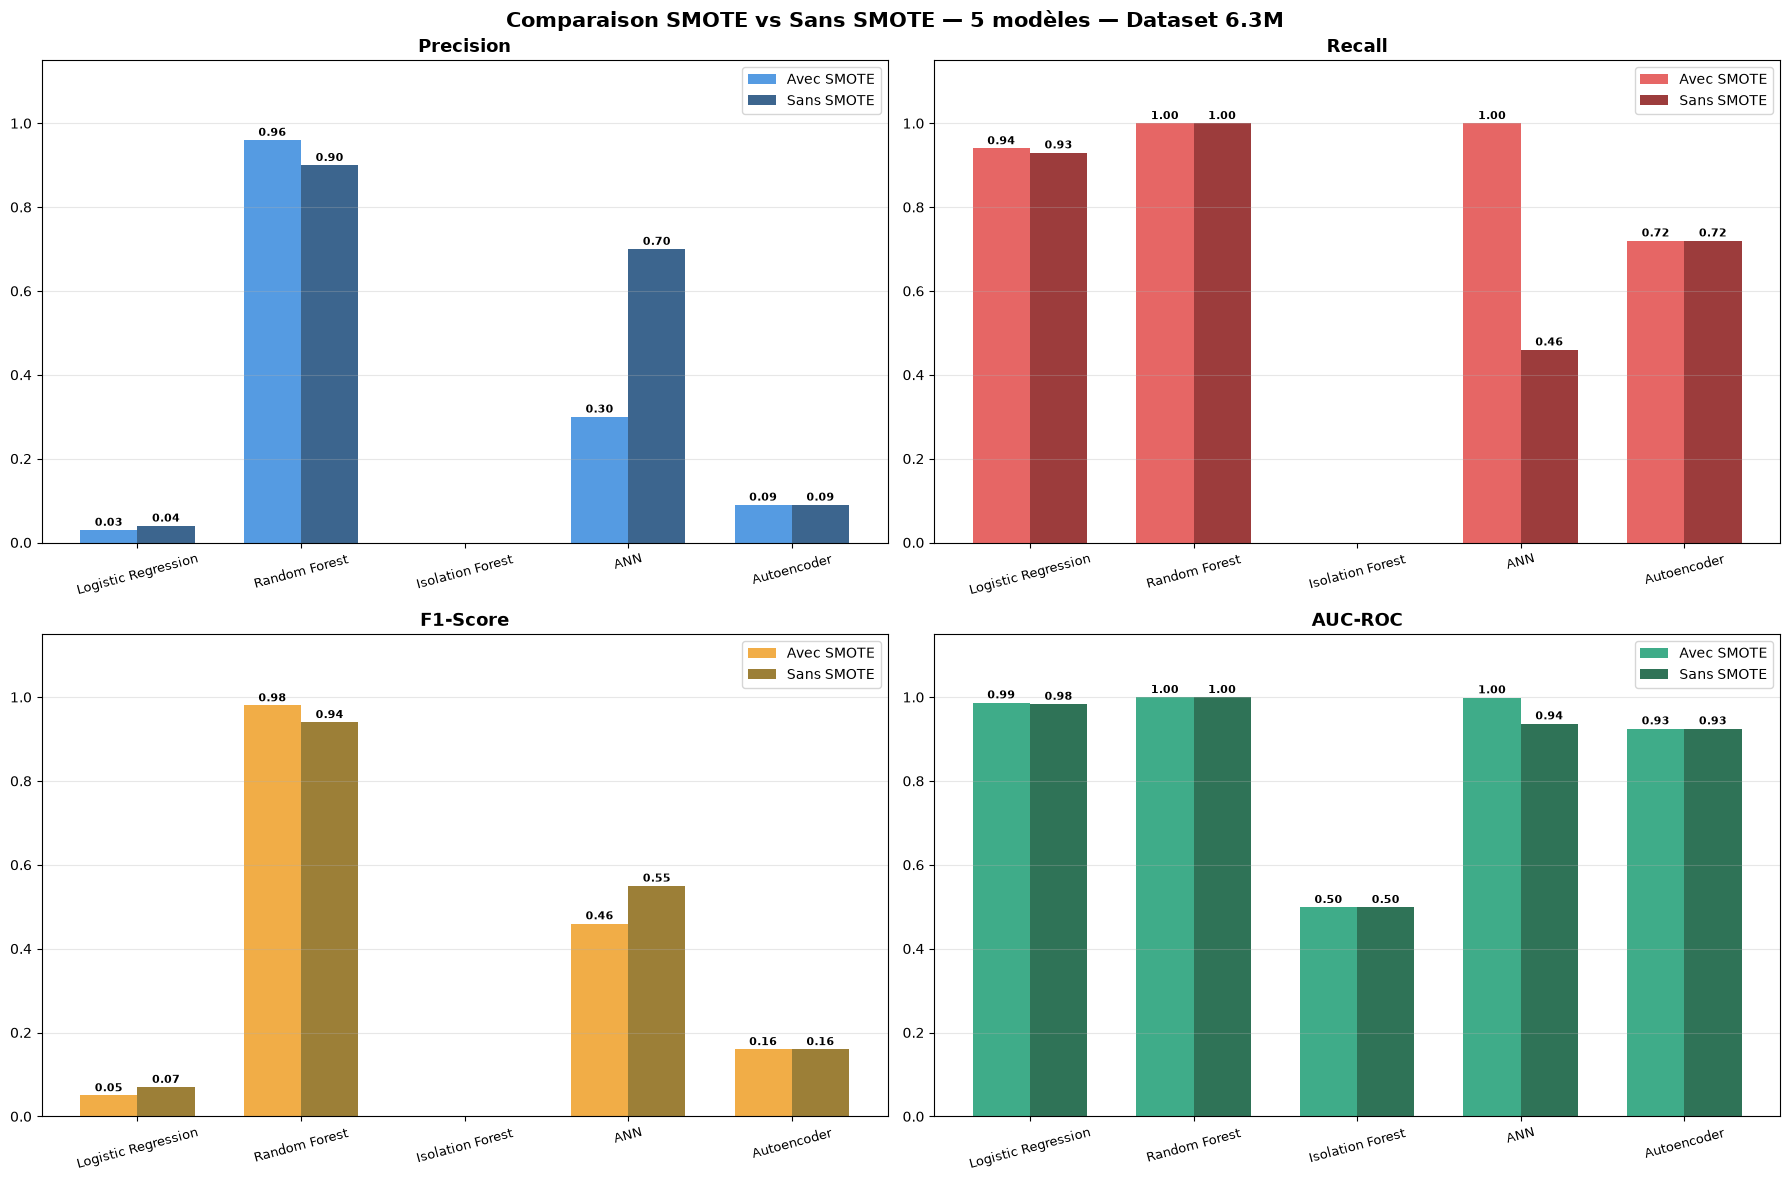

✅ Graphique sauvegardé → Models/smote_vs_sans_smote.png


In [7]:
import matplotlib.pyplot as plt
import numpy as np

# ── Résultats AVEC SMOTE (anciens résultats) ──────────────────
results_smote = {
    'Logistic Regression': {'Precision': 0.03, 'Recall': 0.94, 'F1-Score': 0.05, 'AUC-ROC': 0.987},
    'Random Forest':       {'Precision': 0.96, 'Recall': 1.00, 'F1-Score': 0.98, 'AUC-ROC': 0.9998},
    'Isolation Forest':    {'Precision': 0.00, 'Recall': 0.00, 'F1-Score': 0.00, 'AUC-ROC': 0.499},
    'ANN':                 {'Precision': 0.30, 'Recall': 1.00, 'F1-Score': 0.46, 'AUC-ROC': 0.999},
    'Autoencoder':         {'Precision': 0.09, 'Recall': 0.72, 'F1-Score': 0.16, 'AUC-ROC': 0.925},
}

# ── Résultats SANS SMOTE (nouveaux résultats) ─────────────────
results_sans_smote = {
    'Logistic Regression': {'Precision': 0.04, 'Recall': 0.93, 'F1-Score': 0.07, 'AUC-ROC': 0.9836},
    'Random Forest':       {'Precision': 0.90, 'Recall': 1.00, 'F1-Score': 0.94, 'AUC-ROC': 0.9998},
    'Isolation Forest':    {'Precision': 0.00, 'Recall': 0.00, 'F1-Score': 0.00, 'AUC-ROC': 0.499},
    'ANN':                 {'Precision': 0.70, 'Recall': 0.46, 'F1-Score': 0.55, 'AUC-ROC': 0.937},
    'Autoencoder':         {'Precision': 0.09, 'Recall': 0.72, 'F1-Score': 0.16, 'AUC-ROC': 0.925},
}

models = list(results_smote.keys())
metrics = ['Precision', 'Recall', 'F1-Score', 'AUC-ROC']
colors_smote     = ['#378ADD', '#E24B4A', '#EF9F27', '#1D9E75']
colors_no_smote  = ['#1A4A7A', '#8B1A1A', '#8B6914', '#0A5A3A']

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Comparaison SMOTE vs Sans SMOTE — 5 modèles — Dataset 6.3M',
             fontsize=15, fontweight='bold')

for idx, (metric, ax) in enumerate(zip(metrics, axes.flatten())):
    x = np.arange(len(models))
    width = 0.35

    vals_smote    = [results_smote[m][metric] for m in models]
    vals_no_smote = [results_sans_smote[m][metric] for m in models]

    bars1 = ax.bar(x - width/2, vals_smote,    width,
                   label='Avec SMOTE',    color=colors_smote[idx],    alpha=0.85)
    bars2 = ax.bar(x + width/2, vals_no_smote, width,
                   label='Sans SMOTE',   color=colors_no_smote[idx], alpha=0.85)

    # Valeurs sur les barres
    for bar in bars1:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.01,
                    f'{h:.2f}', ha='center', fontsize=8, fontweight='bold')
    for bar in bars2:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.01,
                    f'{h:.2f}', ha='center', fontsize=8, fontweight='bold')

    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=15, fontsize=9)
    ax.set_ylim(0, 1.15)
    ax.set_title(f'{metric}', fontsize=13, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../Models/smote_vs_sans_smote.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Graphique sauvegardé → Models/smote_vs_sans_smote.png")